# Devoir 3 — Implémentation et Comparaison des Architectures RAG
## Sujet : Génération de Règles SNORT via NLP + RAG

**Étudiant :** Louai EdDiaz  
**Prof :** Ikram BEN ABDEL OUAHAB  
**Année :** 2026

---

### Objectif
Implémenter et comparer **7 architectures RAG** appliquées à la génération automatique de règles Snort à partir de descriptions en langage naturel d'attaques réseau.

### Architectures couvertes
| # | Architecture | Description |
|---|---|---|
| 0 | **LLM sans RAG** | Baseline — génération directe sans retrieval |
| 1 | **RAG Classique** | FAISS + embeddings denses + top-k |
| 2 | **RAG + Re-ranking** | Cross-encoder pour re-scorer les candidats |
| 3 | **RAG Hybride** | BM25 (sparse) + FAISS (dense) fusionnés |
| 4 | **Multi-hop RAG** | Retrieval itératif avec reformulation de requête |
| 5 | **Graph RAG** | Graphe de connaissances NetworkX sur familles d'attaques |
| 6 | **Agentic RAG** | Agent décisionnel avec boucle de raisonnement |


## 1. Installation et Imports

In [2]:
# Installation des dépendances (exécuter une seule fois)
# !pip install sentence-transformers faiss-cpu rank-bm25 networkx rouge-score nltk gradio mlx mlx-lm bert-score tqdm pandas


In [3]:
import json, time, re, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import networkx as nx
from pathlib import Path
from collections import defaultdict, Counter
from tqdm import tqdm

# Embeddings & retrieval
from sentence_transformers import SentenceTransformer, CrossEncoder
import faiss
from rank_bm25 import BM25Okapi

# Metrics
from rouge_score import rouge_scorer
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
import nltk
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
from sklearn.manifold import TSNE
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import LabelEncoder

# UI
import gradio as gr

warnings.filterwarnings('ignore')
print("✓ Imports OK")


✓ Imports OK


## 2. Dataset

Notre dataset contient **200 règles Snort** réelles couvrant 8 familles d'attaques réseau, 
construit manuellement à partir des règles communautaires Snort et des CVEs connues.

**Format par entrée :**
```json
{
  "id": 1000001,
  "description": "Detect SYN port scan targeting any host",
  "snort_rule": "alert tcp any any -> $HOME_NET any (...)",
  "attack_type": "syn_scan",
  "attack_family": "port_scanning",
  "protocol": "tcp",
  "keywords": ["SYN", "scan", "reconnaissance"],
  "reference": "CVE-general"
}
```


In [4]:
# Charger le dataset
DATASET_PATH = Path("dataset/snort_dataset.json")
with open(DATASET_PATH, encoding="utf-8") as f:
    dataset = json.load(f)

df = pd.DataFrame(dataset)
print(f"Dataset: {len(df)} règles Snort")
print(f"Familles d'attaques: {df['attack_family'].nunique()}")
print()
print(df.groupby('attack_family')['id'].count().rename('count').to_string())


Dataset: 200 règles Snort
Familles d'attaques: 8

attack_family
brute_force          22
data_exfiltration    20
dos_ddos             25
intrusion            20
malware_c2           25
network_exploit      25
port_scanning        28
web_attack           35


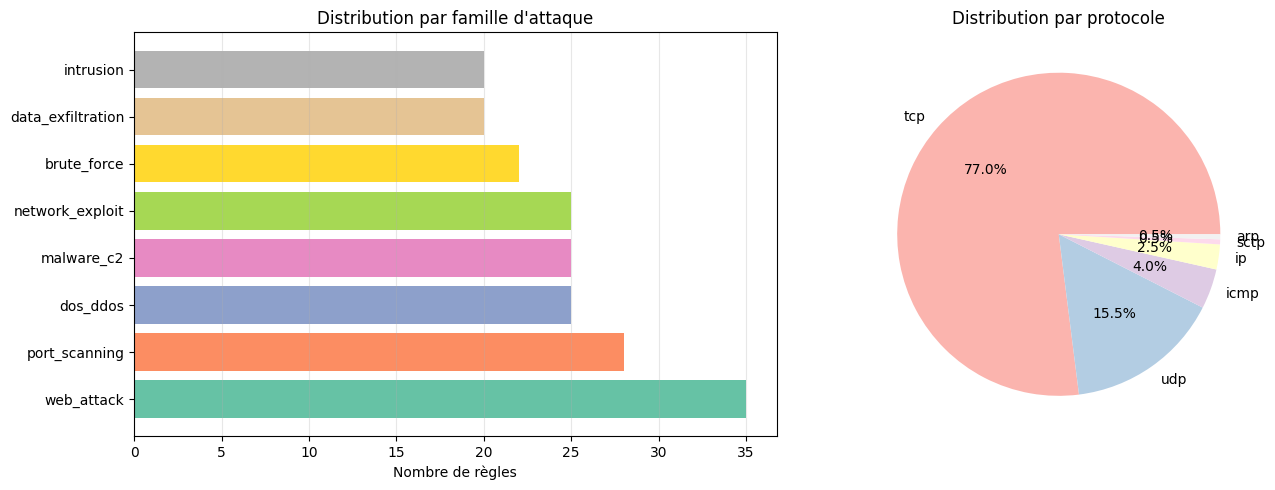

Distribution sauvegardée.


In [5]:
# Visualiser la distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart par famille
family_counts = df['attack_family'].value_counts()
axes[0].barh(family_counts.index, family_counts.values, 
             color=plt.cm.Set2(np.linspace(0, 1, len(family_counts))))
axes[0].set_xlabel('Nombre de règles')
axes[0].set_title('Distribution par famille d\'attaque')
axes[0].grid(axis='x', alpha=0.3)

# Protocol distribution
proto_counts = df['protocol'].value_counts()
axes[1].pie(proto_counts.values, labels=proto_counts.index, autopct='%1.1f%%',
            colors=plt.cm.Pastel1(np.linspace(0, 1, len(proto_counts))))
axes[1].set_title('Distribution par protocole')

plt.tight_layout()
plt.savefig('dataset_distribution.png', dpi=120, bbox_inches='tight')
plt.show()
print("Distribution sauvegardée.")


In [6]:
# Préparer train/test split
# 15 entrées de test (réparties sur toutes les familles), 185 pour la base de connaissances
np.random.seed(42)

test_indices = []
for family in df['attack_family'].unique():
    family_idx = df[df['attack_family'] == family].index.tolist()
    n_test = max(1, len(family_idx) // 6)
    test_indices.extend(np.random.choice(family_idx, n_test, replace=False).tolist())

test_indices = list(set(test_indices))[:15]  # cap at 15
train_indices = [i for i in df.index if i not in test_indices]

train_df = df.iloc[train_indices].reset_index(drop=True)
test_df  = df.iloc[test_indices].reset_index(drop=True)

# Documents = descriptions (ce que l'on indexe)
documents     = train_df['description'].tolist()
rules         = train_df['snort_rule'].tolist()
families      = train_df['attack_family'].tolist()
attack_types  = train_df['attack_type'].tolist()
keywords_list = train_df['keywords'].tolist()

print(f"Train (base de connaissances) : {len(train_df)} règles")
print(f"Test  (évaluation)           : {len(test_df)} règles")
print(f"\nExemple test query : '{test_df['description'].iloc[0]}'")


Train (base de connaissances) : 185 règles
Test  (évaluation)           : 15 règles

Exemple test query : 'Detect Agent Tesla spyware credential theft POST'


## 3. Configuration du LLM Local

Nous utilisons **Mistral-7B-Instruct** via **MLX** (framework Apple Silicon optimisé pour M2).  
Cela respecte la contrainte : **aucun appel API externe**.

> Le modèle (~4 Go) est téléchargé une seule fois depuis HuggingFace Hub et stocké localement.


In [7]:
# ─── LLM Local via MLX (Apple M2 optimisé) ───────────────────────────────────
try:
    from mlx_lm import load, generate as mlx_generate
    
    print("Chargement Mistral-7B-Instruct-v0.3-4bit via MLX...")
    print("(Premier lancement : téléchargement ~4 Go)")
    
    LLM_MODEL, LLM_TOKENIZER = load("mlx-community/Mistral-7B-Instruct-v0.3-4bit")
    LLM_BACKEND = "mlx"
    print(f"✓ LLM chargé via MLX : Mistral-7B-Instruct-v0.3-4bit")

except ImportError:
    # Fallback: HuggingFace transformers (CPU)
    print("MLX non disponible. Fallback → HuggingFace transformers (TinyLlama)")
    from transformers import pipeline
    LLM_PIPE = pipeline(
        "text-generation",
        model="TinyLlama/TinyLlama-1.1B-Chat-v1.0",
        max_new_tokens=256,
        do_sample=False,
        temperature=1.0
    )
    LLM_BACKEND = "hf"
    print("✓ LLM chargé via HuggingFace : TinyLlama-1.1B-Chat")


Chargement Mistral-7B-Instruct-v0.3-4bit via MLX...
(Premier lancement : téléchargement ~4 Go)


Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

✓ LLM chargé via MLX : Mistral-7B-Instruct-v0.3-4bit


In [8]:
# ─── Fonction de génération unifiée ──────────────────────────────────────────
SYSTEM_PROMPT = (
    "You are a network security expert specializing in Snort IDS rules. "
    "When given a description of a network attack, you generate a valid, complete Snort rule. "
    "Snort rule format: action protocol src_ip src_port direction dst_ip dst_port (options;)\n"
    "Always include: msg, classtype, sid, rev. Use proper Snort syntax."
)

def build_prompt(user_query: str, context: str = "") -> str:
    """Construire le prompt pour le LLM."""
    if context:
        user_content = (
            f"Context (similar existing Snort rules):\n{context}\n\n"
            f"Task: Generate a Snort rule for the following attack description:\n{user_query}\n\n"
            f"Generate ONLY the Snort rule, nothing else."
        )
    else:
        user_content = (
            f"Generate a Snort rule for the following attack description:\n{user_query}\n\n"
            f"Generate ONLY the Snort rule, nothing else."
        )

    if LLM_BACKEND == "mlx":
        # Merge system prompt into user message — many models don't support the system role
        messages = [
            {"role": "user", "content": f"{SYSTEM_PROMPT}\n\n{user_content}"}
        ]
        return LLM_TOKENIZER.apply_chat_template(
            messages, tokenize=False, add_generation_prompt=True
        )
    else:
        return f"<|system|>\n{SYSTEM_PROMPT}</s>\n<|user|>\n{user_content}</s>\n<|assistant|>"


def llm_generate(prompt: str, max_tokens: int = 256) -> str:
    """Appel LLM local — retourne le texte généré."""
    if LLM_BACKEND == "mlx":
        return mlx_generate(
            LLM_MODEL, LLM_TOKENIZER,
            prompt=prompt,
            max_tokens=max_tokens,
            verbose=False
        )
    else:
        result = LLM_PIPE(prompt, max_new_tokens=max_tokens)
        return result[0]['generated_text'].split("<|assistant|>")[-1].strip()


def extract_snort_rule(text: str) -> str:
    """Extraire la règle Snort du texte généré."""
    pattern = r'((?:alert|drop|pass|log|reject)\s+(?:tcp|udp|icmp|ip|any)\s+[^\n]+\([^)]+\);?)'
    match = re.search(pattern, text, re.IGNORECASE | re.DOTALL)
    if match:
        return match.group(1).strip()
    return text.strip().split('\n')[0]


def is_valid_snort_rule(rule: str) -> bool:
    """Vérifier si la règle Snort a la structure minimale valide."""
    pattern = r'^(alert|drop|pass|log|reject)\s+(tcp|udp|icmp|ip|any).*\(.*msg:.*sid:\d+.*\)'
    return bool(re.search(pattern, rule, re.IGNORECASE | re.DOTALL))

print("✓ Fonctions LLM configurées")
print(f"  Backend : {LLM_BACKEND}")


✓ Fonctions LLM configurées
  Backend : mlx


In [9]:
# ─── Test rapide du LLM ──────────────────────────────────────────────────────
test_query = "Detect a SYN flood DoS attack targeting a web server on port 80"
prompt = build_prompt(test_query)

t0 = time.time()
raw = llm_generate(prompt, max_tokens=200)
latency = time.time() - t0

rule = extract_snort_rule(raw)
valid = is_valid_snort_rule(rule)

print(f"Query   : {test_query}")
print(f"Rule    : {rule}")
print(f"Valid   : {valid}")
print(f"Latency : {latency:.2f}s")


Query   : Detect a SYN flood DoS attack targeting a web server on port 80
Rule    : alert tcp $EXTERNAL_NET any -> $HTTP_SERVERS 80 (msg:"SYN Flood DoS attack against web server (HTTP)
Valid   : False
Latency : 11.75s


## 4. Embeddings et Index FAISS

Construction de la base vectorielle partagée par toutes les architectures RAG.


In [10]:
# ─── Modèle d'embeddings ─────────────────────────────────────────────────────
print("Chargement du modèle d'embeddings...")
EMBED_MODEL = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')
print(f"✓ Modèle : all-MiniLM-L6-v2  (dim={EMBED_MODEL.get_sentence_embedding_dimension()})")

# ─── Encoder tous les documents ──────────────────────────────────────────────
print("Encodage des documents...")
doc_embeddings = EMBED_MODEL.encode(documents, show_progress_bar=True, normalize_embeddings=True)
print(f"✓ Shape embeddings : {doc_embeddings.shape}")


Chargement du modèle d'embeddings...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

✓ Modèle : all-MiniLM-L6-v2  (dim=384)
Encodage des documents...


Batches:   0%|          | 0/6 [00:00<?, ?it/s]

✓ Shape embeddings : (185, 384)


In [11]:
# ─── Index FAISS ─────────────────────────────────────────────────────────────
DIM = doc_embeddings.shape[1]

# IndexFlatIP = produit scalaire (équivalent cosine sur vecteurs normalisés)
faiss_index = faiss.IndexFlatIP(DIM)
faiss_index.add(doc_embeddings.astype(np.float32))
print(f"✓ FAISS IndexFlatIP : {faiss_index.ntotal} vecteurs indexés")

# ─── BM25 pour retrieval sparse ───────────────────────────────────────────────
tokenized_corpus = [doc.lower().split() for doc in documents]
bm25_index = BM25Okapi(tokenized_corpus)
print(f"✓ BM25 index : {len(tokenized_corpus)} documents")

# ─── Cross-encoder pour re-ranking ───────────────────────────────────────────
print("Chargement cross-encoder pour re-ranking...")
CROSS_ENCODER = CrossEncoder('cross-encoder/ms-marco-MiniLM-L-6-v2')
print("✓ Cross-encoder chargé")


✓ FAISS IndexFlatIP : 185 vecteurs indexés
✓ BM25 index : 185 documents
Chargement cross-encoder pour re-ranking...


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

✓ Cross-encoder chargé


In [12]:
# ─── Fonctions de retrieval de base ──────────────────────────────────────────
def dense_retrieve(query: str, k: int = 5) -> list[dict]:
    """Retrieval dense via FAISS."""
    q_emb = EMBED_MODEL.encode([query], normalize_embeddings=True).astype(np.float32)
    scores, indices = faiss_index.search(q_emb, k)
    results = []
    for score, idx in zip(scores[0], indices[0]):
        if idx >= 0:
            results.append({
                'idx': int(idx),
                'score': float(score),
                'description': documents[idx],
                'rule': rules[idx],
                'family': families[idx],
                'type': attack_types[idx],
            })
    return results


def sparse_retrieve(query: str, k: int = 5) -> list[dict]:
    """Retrieval sparse via BM25."""
    tokens = query.lower().split()
    scores = bm25_index.get_scores(tokens)
    top_k = np.argsort(scores)[::-1][:k]
    results = []
    for idx in top_k:
        results.append({
            'idx': int(idx),
            'score': float(scores[idx]),
            'description': documents[idx],
            'rule': rules[idx],
            'family': families[idx],
            'type': attack_types[idx],
        })
    return results


def build_context(retrieved_docs: list[dict], max_docs: int = 3) -> str:
    """Formater les documents récupérés comme contexte pour le LLM."""
    context_parts = []
    for i, doc in enumerate(retrieved_docs[:max_docs], 1):
        context_parts.append(
            f"[{i}] Description: {doc['description']}\n"
            f"    Rule: {doc['rule']}"
        )
    return "\n\n".join(context_parts)

print("✓ Fonctions de retrieval prêtes")


✓ Fonctions de retrieval prêtes


## 5. Architectures RAG

### 5.0 — LLM sans RAG (Baseline)

In [13]:
# ════════════════════════════════════════════════════════════
# ARCHITECTURE 0 : LLM SANS RAG (Baseline)
# ════════════════════════════════════════════════════════════

def llm_no_rag(query: str) -> dict:
    """
    Baseline : le LLM génère une règle Snort SANS aucun contexte récupéré.
    Aucun retrieval — mesure la connaissance intrinsèque du modèle.
    """
    t0 = time.time()
    prompt = build_prompt(query)
    raw = llm_generate(prompt)
    latency = time.time() - t0
    rule = extract_snort_rule(raw)
    return {
        'architecture': 'LLM_no_RAG',
        'query': query,
        'retrieved_docs': [],
        'context': '',
        'raw_output': raw,
        'generated_rule': rule,
        'valid': is_valid_snort_rule(rule),
        'latency': latency
    }

# Test
print("=== Test : LLM sans RAG ===")
result = llm_no_rag("Detect a SQL injection attack via UNION SELECT in HTTP URI")
print(f"Query   : {result['query']}")
print(f"Rule    : {result['generated_rule']}")
print(f"Valid   : {result['valid']}")
print(f"Latency : {result['latency']:.2f}s")


=== Test : LLM sans RAG ===
Query   : Detect a SQL injection attack via UNION SELECT in HTTP URI
Rule    : ```
Valid   : False
Latency : 14.15s


### 5.1 — RAG Classique (Naïf)

In [14]:
# ════════════════════════════════════════════════════════════
# ARCHITECTURE 1 : RAG CLASSIQUE
# ════════════════════════════════════════════════════════════

def rag_classic(query: str, k: int = 3) -> dict:
    """
    RAG Classique :
    1. Encoder la requête avec sentence-transformers
    2. Rechercher Top-k dans FAISS (similarité cosine)
    3. Construire un prompt enrichi avec le contexte récupéré
    4. Générer la règle Snort via le LLM
    """
    t0 = time.time()
    
    # Retrieval dense
    retrieved = dense_retrieve(query, k=k)
    context = build_context(retrieved)
    
    # Génération
    prompt = build_prompt(query, context)
    raw = llm_generate(prompt)
    latency = time.time() - t0
    
    rule = extract_snort_rule(raw)
    return {
        'architecture': 'RAG_Classic',
        'query': query,
        'retrieved_docs': retrieved,
        'context': context,
        'raw_output': raw,
        'generated_rule': rule,
        'valid': is_valid_snort_rule(rule),
        'latency': latency
    }

# Test
print("=== Test : RAG Classique ===")
result = rag_classic("Detect brute force attack on SSH port 22")
print(f"Query       : {result['query']}")
print(f"Docs récup. : {len(result['retrieved_docs'])} ({[d['type'] for d in result['retrieved_docs']]})")
print(f"Rule        : {result['generated_rule']}")
print(f"Valid       : {result['valid']}")
print(f"Latency     : {result['latency']:.2f}s")


=== Test : RAG Classique ===
Query       : Detect brute force attack on SSH port 22
Docs récup. : 3 (['ssh_brute', 'ssh_reverse_fwd', 'redis_brute'])
Rule        : alert tcp $EXTERNAL_NET any -> $SSH_SERVERS 22 (msg:"ET BRUTE SSH Brute Force"; content:"SSH-"; depth:4; threshold:type both,track by_src,count 5,seconds 60; classtype:attempted-admin; sid:1000089; rev:2;)
Valid       : True
Latency     : 15.34s


### 5.2 — RAG avec Re-ranking

In [15]:
# ════════════════════════════════════════════════════════════
# ARCHITECTURE 2 : RAG + RE-RANKING
# ════════════════════════════════════════════════════════════

def rerank(query: str, candidates: list[dict]) -> list[dict]:
    """
    Re-scoring avec un cross-encoder.
    Le cross-encoder prend (query, document) ensemble et prédit
    un score de pertinence plus précis que la similarité cosine seule.
    """
    pairs = [(query, doc['description']) for doc in candidates]
    scores = CROSS_ENCODER.predict(pairs)
    for doc, score in zip(candidates, scores):
        doc['rerank_score'] = float(score)
    return sorted(candidates, key=lambda x: x['rerank_score'], reverse=True)


def rag_rerank(query: str, k_retrieve: int = 10, k_final: int = 3) -> dict:
    """
    RAG + Re-ranking :
    1. Retrieval large (Top-10 candidats) via FAISS
    2. Re-scoring avec cross-encoder ms-marco-MiniLM-L-6-v2
    3. Garder Top-3 après re-ranking
    4. Générer via LLM avec contexte affiné
    """
    t0 = time.time()
    
    # Large retrieval
    candidates = dense_retrieve(query, k=k_retrieve)
    
    # Re-ranking
    reranked = rerank(query, candidates)
    top_docs = reranked[:k_final]
    context = build_context(top_docs)
    
    # Génération
    prompt = build_prompt(query, context)
    raw = llm_generate(prompt)
    latency = time.time() - t0
    
    rule = extract_snort_rule(raw)
    return {
        'architecture': 'RAG_Rerank',
        'query': query,
        'retrieved_docs': top_docs,
        'context': context,
        'raw_output': raw,
        'generated_rule': rule,
        'valid': is_valid_snort_rule(rule),
        'latency': latency,
        'rerank_scores': [d['rerank_score'] for d in top_docs]
    }

# Test
print("=== Test : RAG + Re-ranking ===")
result = rag_rerank("Detect UDP flood DDoS attack overwhelming target bandwidth")
print(f"Query         : {result['query']}")
print(f"Docs récup.   : {len(result['retrieved_docs'])}")
print(f"Rerank scores : {[f'{s:.3f}' for s in result['rerank_scores']]}")
print(f"Rule          : {result['generated_rule']}")
print(f"Valid         : {result['valid']}")
print(f"Latency       : {result['latency']:.2f}s")


=== Test : RAG + Re-ranking ===
Query         : Detect UDP flood DDoS attack overwhelming target bandwidth
Docs récup.   : 3
Rerank scores : ['5.012', '1.103', '0.519']
Rule          : alert udp $EXTERNAL_NET any -> $HOME_NET any (msg:"ET DDoS UDP Flood - Bandwidth Overwhelm"; threshold:type cumulative, track by_src, count 10000, seconds 1; flow:established,to_server; classtype:attempted-dos; sid:1000031; rev:1;)
Valid         : True
Latency       : 15.85s


### 5.3 — RAG Hybride (Dense + Sparse)

In [16]:
# ════════════════════════════════════════════════════════════
# ARCHITECTURE 3 : RAG HYBRIDE (Dense + Sparse)
# ════════════════════════════════════════════════════════════

def reciprocal_rank_fusion(dense_results: list[dict], 
                            sparse_results: list[dict], 
                            k: int = 60,
                            alpha: float = 0.5) -> list[dict]:
    """
    Reciprocal Rank Fusion (RRF) pour fusionner les scores dense et sparse.
    RRF_score = alpha * 1/(k + rank_dense) + (1-alpha) * 1/(k + rank_sparse)
    """
    scores = defaultdict(float)
    doc_map = {}
    
    for rank, doc in enumerate(dense_results):
        idx = doc['idx']
        scores[idx] += alpha * (1.0 / (k + rank + 1))
        doc_map[idx] = doc
    
    for rank, doc in enumerate(sparse_results):
        idx = doc['idx']
        scores[idx] += (1 - alpha) * (1.0 / (k + rank + 1))
        if idx not in doc_map:
            doc_map[idx] = doc
    
    sorted_ids = sorted(scores.keys(), key=lambda x: scores[x], reverse=True)
    results = []
    for idx in sorted_ids:
        doc = doc_map[idx].copy()
        doc['rrf_score'] = scores[idx]
        results.append(doc)
    return results


def hybrid_retrieve(query: str, k: int = 10) -> list[dict]:
    """Fusion dense + sparse avec RRF."""
    dense_results  = dense_retrieve(query, k=k)
    sparse_results = sparse_retrieve(query, k=k)
    return reciprocal_rank_fusion(dense_results, sparse_results)


def rag_hybrid(query: str, k: int = 3) -> dict:
    """
    RAG Hybride :
    1. Retrieval dense (FAISS / cosine similarity)
    2. Retrieval sparse (BM25)
    3. Fusion des rangs via Reciprocal Rank Fusion (RRF)
    4. Génération LLM avec le meilleur contexte fusionné
    """
    t0 = time.time()
    
    fused = hybrid_retrieve(query, k=10)
    top_docs = fused[:k]
    context = build_context(top_docs)
    
    prompt = build_prompt(query, context)
    raw = llm_generate(prompt)
    latency = time.time() - t0
    
    rule = extract_snort_rule(raw)
    return {
        'architecture': 'RAG_Hybrid',
        'query': query,
        'retrieved_docs': top_docs,
        'context': context,
        'raw_output': raw,
        'generated_rule': rule,
        'valid': is_valid_snort_rule(rule),
        'latency': latency,
        'rrf_scores': [d['rrf_score'] for d in top_docs]
    }

# Test
print("=== Test : RAG Hybride ===")
result = rag_hybrid("Detect XSS attack using JavaScript script tag in HTTP URI parameter")
print(f"Query      : {result['query']}")
print(f"Docs récup.: {len(result['retrieved_docs'])} (RRF fusion dense+sparse)")
print(f"RRF scores : {[f'{s:.4f}' for s in result['rrf_scores']]}")
print(f"Rule       : {result['generated_rule']}")
print(f"Valid      : {result['valid']}")
print(f"Latency    : {result['latency']:.2f}s")


=== Test : RAG Hybride ===
Query      : Detect XSS attack using JavaScript script tag in HTTP URI parameter
Docs récup.: 3 (RRF fusion dense+sparse)
RRF scores : ['0.0164', '0.0161', '0.0155']
Rule       : alert tcp $EXTERNAL_NET any -> $HTTP_SERVERS $HTTP_PORTS (msg:"ET WEB XSS Script Tag in URI"; content:"<script"; http_uri; nocase; classtype:web-application-attack; sid:1000059; rev:1;)
Valid      : True
Latency    : 15.30s


### 5.4 — Multi-hop RAG

In [17]:
# ════════════════════════════════════════════════════════════
# ARCHITECTURE 4 : MULTI-HOP RAG
# ════════════════════════════════════════════════════════════

def reformulate_query(original_query: str, hop1_context: str) -> str:
    """
    Le LLM reformule la requête basé sur les documents récupérés au hop 1.
    Identifie les aspects manquants pour le hop 2.
    """
    refine_prompt_text = (
        f"Original query: {original_query}\n\n"
        f"Documents already found:\n{hop1_context}\n\n"
        f"Based on these documents, generate a refined follow-up search query "
        f"to find additional relevant Snort rules that complement what was found. "
        f"Output ONLY the refined query, nothing else."
    )
    refine_prompt = build_prompt(refine_prompt_text)
    refined = llm_generate(refine_prompt, max_tokens=60)
    # Nettoyer: prendre juste la première ligne non-vide
    lines = [l.strip() for l in refined.split('\n') if l.strip()]
    return lines[0] if lines else original_query


def multi_hop_rag(query: str, n_hops: int = 2, k_per_hop: int = 3) -> dict:
    """
    Multi-hop RAG :
    Hop 1 : Retrieval sur la requête originale
    Reformulation : Le LLM génère une sous-requête basée sur hop 1
    Hop 2 : Retrieval sur la sous-requête
    Fusion : Merger et dédupliquer les contextes des deux hops
    Génération : LLM avec contexte enrichi multi-hop
    """
    t0 = time.time()
    
    all_docs = []
    seen_idx = set()
    hop_queries = [query]
    
    for hop in range(n_hops):
        current_query = hop_queries[-1]
        retrieved = dense_retrieve(current_query, k=k_per_hop)
        
        for doc in retrieved:
            if doc['idx'] not in seen_idx:
                doc['hop'] = hop + 1
                all_docs.append(doc)
                seen_idx.add(doc['idx'])
        
        if hop < n_hops - 1:
            hop1_context = build_context(retrieved)
            refined_query = reformulate_query(query, hop1_context)
            hop_queries.append(refined_query)
    
    context = build_context(all_docs, max_docs=k_per_hop * n_hops)
    
    prompt = build_prompt(query, context)
    raw = llm_generate(prompt)
    latency = time.time() - t0
    
    rule = extract_snort_rule(raw)
    return {
        'architecture': 'Multi_Hop_RAG',
        'query': query,
        'hop_queries': hop_queries,
        'retrieved_docs': all_docs,
        'context': context,
        'raw_output': raw,
        'generated_rule': rule,
        'valid': is_valid_snort_rule(rule),
        'latency': latency,
        'n_hops': n_hops
    }

# Test
print("=== Test : Multi-hop RAG ===")
result = multi_hop_rag("Detect ransomware encrypting files over SMB network share")
print(f"Query originale : {result['query']}")
for i, q in enumerate(result['hop_queries'], 1):
    print(f"  Hop {i} query : {q}")
print(f"Docs totaux  : {len(result['retrieved_docs'])}")
print(f"Rule         : {result['generated_rule']}")
print(f"Valid        : {result['valid']}")
print(f"Latency      : {result['latency']:.2f}s")


=== Test : Multi-hop RAG ===
Query originale : Detect ransomware encrypting files over SMB network share
  Hop 1 query : Detect ransomware encrypting files over SMB network share
  Hop 2 query : query "ransomware SMB file modification AND NOT scheduled task creation AND NOT unauthorized access to admin share C$"
Docs totaux  : 3
Rule         : alert tcp $HOME_NET any -> $HOME_NET 445 (msg:"ET MALWARE Ransomware SMB File Encryption"; content:"|ff|SMB|a2|"; depth:8; threshold:type both,track by_src,count 100,seconds 10; content:"|ff|SMB|a1|"; within 10; content:"|ff|SMB|a3|"; within 10; classtype:trojan-activity; sid:1000119; rev:1;)
Valid        : True
Latency      : 19.70s


### 5.5 — Graph RAG

In [18]:
# ════════════════════════════════════════════════════════════
# ARCHITECTURE 5 : GRAPH RAG
# ════════════════════════════════════════════════════════════

def build_knowledge_graph(docs_df: pd.DataFrame) -> nx.DiGraph:
    """
    Construire un graphe de connaissances :
    - Noeuds familles d'attaque (attack_family)
    - Noeuds types d'attaque (attack_type)
    - Noeuds règles individuelles (rule_{id})
    - Arêtes : family → type → rule
    - Arêtes de co-occurrence : règles partageant des keywords
    """
    G = nx.DiGraph()
    
    # Familles comme super-noeuds
    for family in docs_df['attack_family'].unique():
        G.add_node(family, node_type='family', label=family)
    
    # Types d'attaque
    for _, row in docs_df.iterrows():
        rule_node = f"rule_{row['id']}"
        G.add_node(rule_node,
                   node_type='rule',
                   description=row['description'],
                   rule=row['snort_rule'],
                   attack_type=row['attack_type'],
                   family=row['attack_family'],
                   protocol=row['protocol'],
                   keywords=row['keywords'])
        
        # Edges hiérarchiques
        G.add_edge(row['attack_family'], rule_node, relation='contains')
        
        # Edges protocole (noeud partagé par règles du même protocole)
        proto_node = f"proto_{row['protocol']}"
        G.add_node(proto_node, node_type='protocol', label=row['protocol'])
        G.add_edge(rule_node, proto_node, relation='uses_protocol')
    
    # Arêtes de co-occurrence par keywords communs
    rule_nodes = [(n, d) for n, d in G.nodes(data=True) if d.get('node_type') == 'rule']
    kw_to_rules = defaultdict(list)
    for node, data in rule_nodes:
        for kw in data.get('keywords', []):
            kw_to_rules[kw.lower()].append(node)
    
    for kw, nodes in kw_to_rules.items():
        if len(nodes) > 1:
            for i in range(len(nodes)):
                for j in range(i+1, min(i+3, len(nodes))):
                    if not G.has_edge(nodes[i], nodes[j]):
                        G.add_edge(nodes[i], nodes[j], relation='shares_keyword', keyword=kw)
    
    return G


print("Construction du graphe de connaissances...")
KG = build_knowledge_graph(train_df)

rule_nodes = [n for n, d in KG.nodes(data=True) if d.get('node_type') == 'rule']
family_nodes = [n for n, d in KG.nodes(data=True) if d.get('node_type') == 'family']
print(f"✓ Graphe construit :")
print(f"  Noeuds totaux   : {KG.number_of_nodes()}")
print(f"  Noeuds familles : {len(family_nodes)}")
print(f"  Noeuds règles   : {len(rule_nodes)}")
print(f"  Arêtes          : {KG.number_of_edges()}")


Construction du graphe de connaissances...
✓ Graphe construit :
  Noeuds totaux   : 199
  Noeuds familles : 8
  Noeuds règles   : 185
  Arêtes          : 719


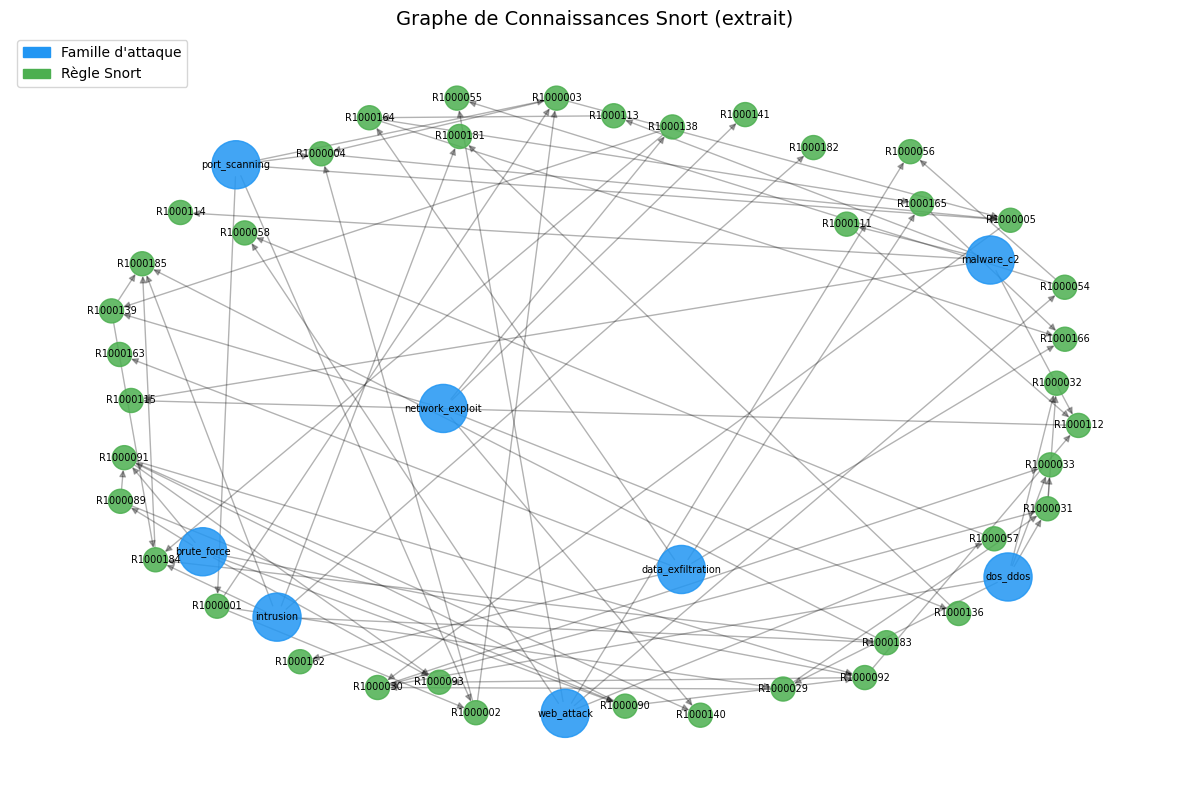

In [19]:
# Visualisation du graphe (familles uniquement pour lisibilité)
plt.figure(figsize=(12, 8))

# Sous-graphe famille → règle (max 5 règles par famille)
viz_nodes = list(family_nodes)
for fam in family_nodes:
    children = list(KG.successors(fam))[:5]
    viz_nodes.extend(children)

subG = KG.subgraph(viz_nodes)
pos = nx.spring_layout(subG, seed=42, k=2.5)

colors = []
sizes  = []
for n in subG.nodes():
    ntype = subG.nodes[n].get('node_type', 'rule')
    if ntype == 'family':
        colors.append('#2196F3')
        sizes.append(1200)
    else:
        colors.append('#4CAF50')
        sizes.append(300)

nx.draw_networkx_nodes(subG, pos, node_color=colors, node_size=sizes, alpha=0.85)
nx.draw_networkx_edges(subG, pos, alpha=0.3, arrows=True, arrowsize=10)
nx.draw_networkx_labels(subG, pos,
    labels={n: n.replace('rule_', 'R') if 'rule_' in n else n 
            for n in subG.nodes()},
    font_size=7)

legend = [
    mpatches.Patch(color='#2196F3', label='Famille d\'attaque'),
    mpatches.Patch(color='#4CAF50', label='Règle Snort')
]
plt.legend(handles=legend, loc='upper left')
plt.title('Graphe de Connaissances Snort (extrait)', fontsize=14)
plt.axis('off')
plt.tight_layout()
plt.savefig('knowledge_graph.png', dpi=120, bbox_inches='tight')
plt.show()


In [20]:
def graph_retrieve(query: str, k: int = 5) -> list[dict]:
    """
    Retrieval via le graphe de connaissances :
    1. Dense retrieve pour trouver le noeud d'entrée le plus proche
    2. Explorer les voisins (1-hop) dans le graphe
    3. Retourner l'ensemble voisins + noeud initial
    """
    # Noeud d'entrée
    seed_docs = dense_retrieve(query, k=2)
    
    enriched = list(seed_docs)
    seen_idx = {d['idx'] for d in seed_docs}
    
    for seed in seed_docs:
        rule_node = f"rule_{train_df.iloc[seed['idx']]['id']}"
        if rule_node not in KG:
            continue
        
        # Voisins directs (partagent des keywords ou même famille)
        neighbors = list(KG.predecessors(rule_node)) + list(KG.successors(rule_node))
        
        for neighbor in neighbors:
            if not KG.nodes[neighbor].get('node_type') == 'rule':
                continue
            # Trouver l'index dans train_df
            neighbor_id = int(neighbor.replace('rule_', ''))
            idx_match = train_df[train_df['id'] == neighbor_id].index
            if len(idx_match) == 0:
                continue
            idx = idx_match[0]
            if idx not in seen_idx:
                enriched.append({
                    'idx': int(idx),
                    'score': 0.5,  # score proxy pour voisins de graphe
                    'description': documents[idx],
                    'rule': rules[idx],
                    'family': families[idx],
                    'type': attack_types[idx],
                    'via_graph': True
                })
                seen_idx.add(idx)
    
    return enriched[:k]


def graph_rag(query: str, k: int = 3) -> dict:
    """
    Graph RAG :
    1. Trouver le noeud de règle le plus proche dans le graphe
    2. Explorer les voisins (rules liées par famille ou keywords)
    3. Générer avec le contexte enrichi par le graphe
    """
    t0 = time.time()
    
    retrieved = graph_retrieve(query, k=k)
    context = build_context(retrieved)
    
    prompt = build_prompt(query, context)
    raw = llm_generate(prompt)
    latency = time.time() - t0
    
    rule = extract_snort_rule(raw)
    return {
        'architecture': 'Graph_RAG',
        'query': query,
        'retrieved_docs': retrieved,
        'context': context,
        'raw_output': raw,
        'generated_rule': rule,
        'valid': is_valid_snort_rule(rule),
        'latency': latency,
        'graph_nodes_explored': len(retrieved)
    }

# Test
print("=== Test : Graph RAG ===")
result = graph_rag("Detect DNS cache poisoning to redirect traffic to malicious server")
print(f"Query          : {result['query']}")
print(f"Noeuds explorés: {result['graph_nodes_explored']}")
print(f"Rule           : {result['generated_rule']}")
print(f"Valid          : {result['valid']}")
print(f"Latency        : {result['latency']:.2f}s")


=== Test : Graph RAG ===
Query          : Detect DNS cache poisoning to redirect traffic to malicious server
Noeuds explorés: 3
Rule           : alert udp $EXTERNAL_NET any -> $HOME_NET 53 (msg:"ET DNS Cache Poisoning Attempt"; content:"|00 01 00 01|"; offset:14; classtype:attempted-dos; sid:1000036; rev:1;)
Valid          : True
Latency        : 9.31s


### 5.6 — Agentic RAG

In [21]:
# ════════════════════════════════════════════════════════════
# ARCHITECTURE 6 : AGENTIC RAG
# ════════════════════════════════════════════════════════════

def agent_assess_confidence(query: str, generated_rule: str, context: str) -> float:
    """
    L'agent évalue la qualité de la règle générée sur une échelle 0-1.
    Critères : validité syntaxique, pertinence sémantique, complétude.
    """
    score = 0.0
    
    # Critère 1 : validité syntaxique
    if is_valid_snort_rule(generated_rule):
        score += 0.4
    
    # Critère 2 : protocole mentionné dans la query présent dans la rule
    query_lower = query.lower()
    rule_lower  = generated_rule.lower()
    for proto in ['tcp', 'udp', 'icmp', 'http', 'ssh', 'ftp', 'dns', 'smb']:
        if proto in query_lower and proto in rule_lower:
            score += 0.15
            break
    
    # Critère 3 : keywords de la query dans la rule
    query_words = set(query_lower.split())
    rule_words  = set(rule_lower.split())
    overlap = len(query_words & rule_words) / max(len(query_words), 1)
    score += min(0.25, overlap * 0.5)
    
    # Critère 4 : règles de base présentes (msg, sid, classtype)
    required_fields = ['msg:', 'sid:', 'classtype:']
    found = sum(1 for f in required_fields if f in generated_rule)
    score += (found / len(required_fields)) * 0.2
    
    return min(1.0, score)


def agentic_rag(query: str, 
                confidence_threshold: float = 0.7, 
                max_iterations: int = 3,
                k: int = 3) -> dict:
    """
    Agentic RAG :
    1. L'agent décide s'il a besoin de retrieval (toujours oui ici pour la robustesse)
    2. Boucle : retrieve → générer → évaluer la confiance
    3. Si confiance < seuil : enrichir le contexte et régénérer (max 3 iterations)
    4. Retourner la meilleure règle générée
    """
    t0 = time.time()
    
    iterations = []
    best_rule   = ""
    best_score  = 0.0
    context     = ""
    all_docs    = []
    seen_idx    = set()
    
    for iteration in range(max_iterations):
        # Retrieval (enrichi à chaque itération)
        if iteration == 0:
            retrieved = dense_retrieve(query, k=k)
        else:
            # Stratégie : mélanger dense et sparse pour diversifier
            dense_docs  = dense_retrieve(query, k=k+iteration)
            sparse_docs = sparse_retrieve(query, k=k+iteration)
            all_candidates = {d['idx']: d for d in dense_docs + sparse_docs}
            retrieved = list(all_candidates.values())[:k + iteration]
        
        # Fusionner avec docs précédents (sans doublons)
        for doc in retrieved:
            if doc['idx'] not in seen_idx:
                all_docs.append(doc)
                seen_idx.add(doc['idx'])
        
        context = build_context(all_docs, max_docs=k + iteration)
        
        # Génération
        prompt = build_prompt(query, context)
        raw = llm_generate(prompt)
        rule = extract_snort_rule(raw)
        
        # Évaluation de la confiance
        confidence = agent_assess_confidence(query, rule, context)
        
        iterations.append({
            'iteration': iteration + 1,
            'rule': rule,
            'confidence': confidence,
            'n_docs': len(all_docs)
        })
        
        if confidence > best_score:
            best_score = confidence
            best_rule  = rule
        
        # Arrêt si seuil atteint
        if confidence >= confidence_threshold:
            break
    
    latency = time.time() - t0
    return {
        'architecture': 'Agentic_RAG',
        'query': query,
        'retrieved_docs': all_docs,
        'context': context,
        'raw_output': best_rule,
        'generated_rule': best_rule,
        'valid': is_valid_snort_rule(best_rule),
        'latency': latency,
        'iterations': iterations,
        'final_confidence': best_score,
        'n_iterations': len(iterations)
    }

# Test
print("=== Test : Agentic RAG ===")
result = agentic_rag("Detect Cobalt Strike C2 beacon HTTPS communication")
print(f"Query          : {result['query']}")
print(f"Itérations     : {result['n_iterations']}")
for it in result['iterations']:
    print(f"  Iter {it['iteration']}: confidence={it['confidence']:.2f}, docs={it['n_docs']}")
print(f"Rule (best)    : {result['generated_rule']}")
print(f"Valid          : {result['valid']}")
print(f"Confiance      : {result['final_confidence']:.2f}")
print(f"Latency        : {result['latency']:.2f}s")


=== Test : Agentic RAG ===
Query          : Detect Cobalt Strike C2 beacon HTTPS communication
Itérations     : 1
  Iter 1: confidence=1.00, docs=3
Rule (best)    : alert tcp $HOME_NET any -> $EXTERNAL_NET 443 (msg:"ET MALWARE Cobalt Strike C2 Beacon HTTPS"; content:"|16 02|"; depth:2; content:"|00 00 00 00|"; classtype:trojan-activity; sid:1000116; rev:1;)
Valid          : True
Confiance      : 1.00
Latency        : 14.97s


## 6. Évaluation et Comparaison

### 6.1 — Métriques d'Évaluation


In [22]:
# ════════════════════════════════════════════════════════════
# MÉTRIQUES D'ÉVALUATION
# ════════════════════════════════════════════════════════════

def compute_bleu(reference: str, hypothesis: str) -> float:
    """BLEU score (nltk) entre la règle de référence et la règle générée."""
    ref_tokens  = reference.lower().split()
    hyp_tokens  = hypothesis.lower().split()
    if not hyp_tokens:
        return 0.0
    smoothing = SmoothingFunction().method1
    try:
        return sentence_bleu([ref_tokens], hyp_tokens, smoothing_function=smoothing)
    except:
        return 0.0


def compute_rouge_l(reference: str, hypothesis: str) -> float:
    """ROUGE-L F1 entre référence et hypothèse."""
    scorer = rouge_scorer.RougeScorer(['rougeL'], use_stemmer=False)
    try:
        scores = scorer.score(reference, hypothesis)
        return scores['rougeL'].fmeasure
    except:
        return 0.0


def compute_answer_relevance(query: str, generated_rule: str) -> float:
    """
    Answer Relevance : similarité cosine entre l'embedding de la requête
    et l'embedding de la règle générée.
    """
    q_emb   = EMBED_MODEL.encode([query], normalize_embeddings=True)
    r_emb   = EMBED_MODEL.encode([generated_rule], normalize_embeddings=True)
    return float(cosine_similarity(q_emb, r_emb)[0][0])


def compute_context_precision(retrieved_docs: list[dict], ground_truth_family: str) -> float:
    """
    Context Precision : proportion des documents récupérés qui appartiennent
    à la même famille d'attaque que la référence.
    """
    if not retrieved_docs:
        return 0.0
    relevant = sum(1 for d in retrieved_docs if d.get('family') == ground_truth_family)
    return relevant / len(retrieved_docs)


def compute_context_recall(retrieved_docs: list[dict], ground_truth_type: str) -> float:
    """
    Context Recall : 1 si au moins un document récupéré correspond au type exact,
    0 sinon (version binaire adaptée à notre dataset).
    """
    if not retrieved_docs:
        return 0.0
    for d in retrieved_docs:
        if d.get('type') == ground_truth_type:
            return 1.0
    return 0.0


def compute_faithfulness(generated_rule: str, retrieved_docs: list[dict]) -> float:
    """
    Faithfulness : proportion des keywords des règles récupérées
    présents dans la règle générée (ancrage dans le contexte).
    """
    if not retrieved_docs:
        return 0.0
    
    context_keywords = set()
    for doc in retrieved_docs:
        # Extraire tokens de la règle récupérée
        rule_tokens = set(re.findall(r'\b[a-zA-Z]{3,}\b', doc['rule'].lower()))
        context_keywords |= rule_tokens
    
    gen_tokens = set(re.findall(r'\b[a-zA-Z]{3,}\b', generated_rule.lower()))
    
    if not context_keywords:
        return 0.0
    
    overlap = len(gen_tokens & context_keywords) / len(context_keywords)
    return min(1.0, overlap)


def compute_snort_validity(rule: str) -> float:
    """Validité syntaxique de la règle Snort (0 ou 1)."""
    return 1.0 if is_valid_snort_rule(rule) else 0.0


def evaluate_result(result: dict, ground_truth: dict) -> dict:
    """Calculer toutes les métriques pour un résultat."""
    ref_rule   = ground_truth['snort_rule']
    query      = result['query']
    gen_rule   = result['generated_rule']
    retrieved  = result.get('retrieved_docs', [])
    gt_family  = ground_truth['attack_family']
    gt_type    = ground_truth['attack_type']
    
    return {
        'architecture':      result['architecture'],
        'query':             query[:60] + '...' if len(query) > 60 else query,
        'BLEU':              round(compute_bleu(ref_rule, gen_rule), 4),
        'ROUGE-L':           round(compute_rouge_l(ref_rule, gen_rule), 4),
        'Answer_Relevance':  round(compute_answer_relevance(query, gen_rule), 4),
        'Context_Precision': round(compute_context_precision(retrieved, gt_family), 4),
        'Context_Recall':    round(compute_context_recall(retrieved, gt_type), 4),
        'Faithfulness':      round(compute_faithfulness(gen_rule, retrieved), 4),
        'Snort_Validity':    round(compute_snort_validity(gen_rule), 4),
        'Latency_s':         round(result.get('latency', 0), 3),
        'generated_rule':    gen_rule[:80] + '...' if len(gen_rule) > 80 else gen_rule,
    }

print("✓ Métriques d'évaluation définies :")
print("  BLEU, ROUGE-L, Answer Relevance, Context Precision,")
print("  Context Recall, Faithfulness, Snort Validity, Latency")


✓ Métriques d'évaluation définies :
  BLEU, ROUGE-L, Answer Relevance, Context Precision,
  Context Recall, Faithfulness, Snort Validity, Latency


### 6.2 — Exécution sur le jeu de test

In [23]:
# ════════════════════════════════════════════════════════════
# PIPELINE D'ÉVALUATION COMPLET
# ════════════════════════════════════════════════════════════

architectures = {
    'LLM_no_RAG':  llm_no_rag,
    'RAG_Classic': rag_classic,
    'RAG_Rerank':  rag_rerank,
    'RAG_Hybrid':  rag_hybrid,
    'Multi_Hop':   multi_hop_rag,
    'Graph_RAG':   graph_rag,
    'Agentic_RAG': agentic_rag,
}

# Requêtes de test (issues du jeu de test)
test_queries = [
    {
        'query': test_df.iloc[i]['description'],
        'ground_truth': test_df.iloc[i].to_dict()
    }
    for i in range(min(15, len(test_df)))
]

# Requêtes manuelles supplémentaires (usage réel)
manual_queries = [
    "Detect SYN port scan targeting web server",
    "Detect SQL injection UNION SELECT in HTTP URI",
    "Detect SSH brute force login attempts",
    "Detect DNS tunneling data exfiltration",
    "Detect Cobalt Strike C2 beacon HTTP communication",
]

print(f"Évaluation sur {len(test_queries)} requêtes de test...")
print("(Cela peut prendre plusieurs minutes selon le LLM)\n")

all_results = []
all_metrics = []

for arch_name, arch_fn in architectures.items():
    print(f"\n--- {arch_name} ---")
    arch_results  = []
    arch_metrics  = []
    
    for item in tqdm(test_queries, desc=arch_name):
        try:
            result = arch_fn(item['query'])
            metrics = evaluate_result(result, item['ground_truth'])
            arch_results.append(result)
            arch_metrics.append(metrics)
        except Exception as e:
            print(f"  Erreur sur '{item['query'][:40]}': {e}")
    
    all_results.extend(arch_results)
    all_metrics.extend(arch_metrics)
    
    if arch_metrics:
        avg_bleu    = np.mean([m['BLEU'] for m in arch_metrics])
        avg_validity = np.mean([m['Snort_Validity'] for m in arch_metrics])
        avg_latency  = np.mean([m['Latency_s'] for m in arch_metrics])
        print(f"  BLEU moyen: {avg_bleu:.4f} | Validité: {avg_validity:.2%} | Latence: {avg_latency:.2f}s")

print("\n✓ Évaluation terminée")


Évaluation sur 15 requêtes de test...
(Cela peut prendre plusieurs minutes selon le LLM)


--- LLM_no_RAG ---


LLM_no_RAG: 100%|██████████| 15/15 [02:36<00:00, 10.46s/it]


  BLEU moyen: 0.1153 | Validité: 66.67% | Latence: 10.35s

--- RAG_Classic ---


RAG_Classic: 100%|██████████| 15/15 [03:32<00:00, 14.14s/it]


  BLEU moyen: 0.3292 | Validité: 80.00% | Latence: 14.04s

--- RAG_Rerank ---


RAG_Rerank: 100%|██████████| 15/15 [04:29<00:00, 17.99s/it]


... (5 outputs left out)

Graph_RAG: 100%|██████████| 15/15 [03:53<00:00, 15.59s/it]


  BLEU moyen: 0.3688 | Validité: 86.67% | Latence: 15.52s

--- Agentic_RAG ---


Agentic_RAG: 100%|██████████| 15/15 [07:21<00:00, 29.41s/it]

  BLEU moyen: 0.3657 | Validité: 86.67% | Latence: 29.34s

✓ Évaluation terminée


### 6.3 — Tableau comparatif des résultats

In [24]:
# ════════════════════════════════════════════════════════════
# TABLEAU COMPARATIF
# ════════════════════════════════════════════════════════════

metrics_df = pd.DataFrame(all_metrics)

# Agréger par architecture (moyennes)
agg_metrics = ['BLEU', 'ROUGE-L', 'Answer_Relevance', 'Context_Precision',
               'Context_Recall', 'Faithfulness', 'Snort_Validity', 'Latency_s']

summary = metrics_df.groupby('architecture')[agg_metrics].mean().round(4)

# Trier par BLEU + ROUGE-L
summary['Score_Global'] = (
    summary['BLEU'] * 0.15 +
    summary['ROUGE-L'] * 0.15 +
    summary['Answer_Relevance'] * 0.20 +
    summary['Context_Precision'] * 0.10 +
    summary['Context_Recall'] * 0.10 +
    summary['Faithfulness'] * 0.15 +
    summary['Snort_Validity'] * 0.15
).round(4)

summary = summary.sort_values('Score_Global', ascending=False)

print("=" * 100)
print("TABLEAU COMPARATIF DES ARCHITECTURES RAG — Génération de Règles Snort")
print("=" * 100)
print(summary.to_string())
print()

# Sauvegarder
summary.to_csv('results_comparison.csv')
print("✓ Tableau sauvegardé : results_comparison.csv")


TABLEAU COMPARATIF DES ARCHITECTURES RAG — Génération de Règles Snort
                 BLEU  ROUGE-L  Answer_Relevance  Context_Precision  Context_Recall  Faithfulness  Snort_Validity  Latency_s  Score_Global
architecture                                                                                                                              
Agentic_RAG    0.3657   0.6160            0.5094             0.5711             0.0        0.4363          0.8667    29.3392        0.5017
Multi_Hop_RAG  0.4131   0.6417            0.4815             0.5811             0.0        0.3779          0.8667    25.9678        0.4993
RAG_Hybrid     0.3921   0.6390            0.4800             0.6000             0.0        0.4044          0.8000    20.4920        0.4913
Graph_RAG      0.3688   0.6297            0.4805             0.5111             0.0        0.4099          0.8667    15.5203        0.4885
RAG_Rerank     0.3753   0.5805            0.4342             0.6222             0.0        0.398

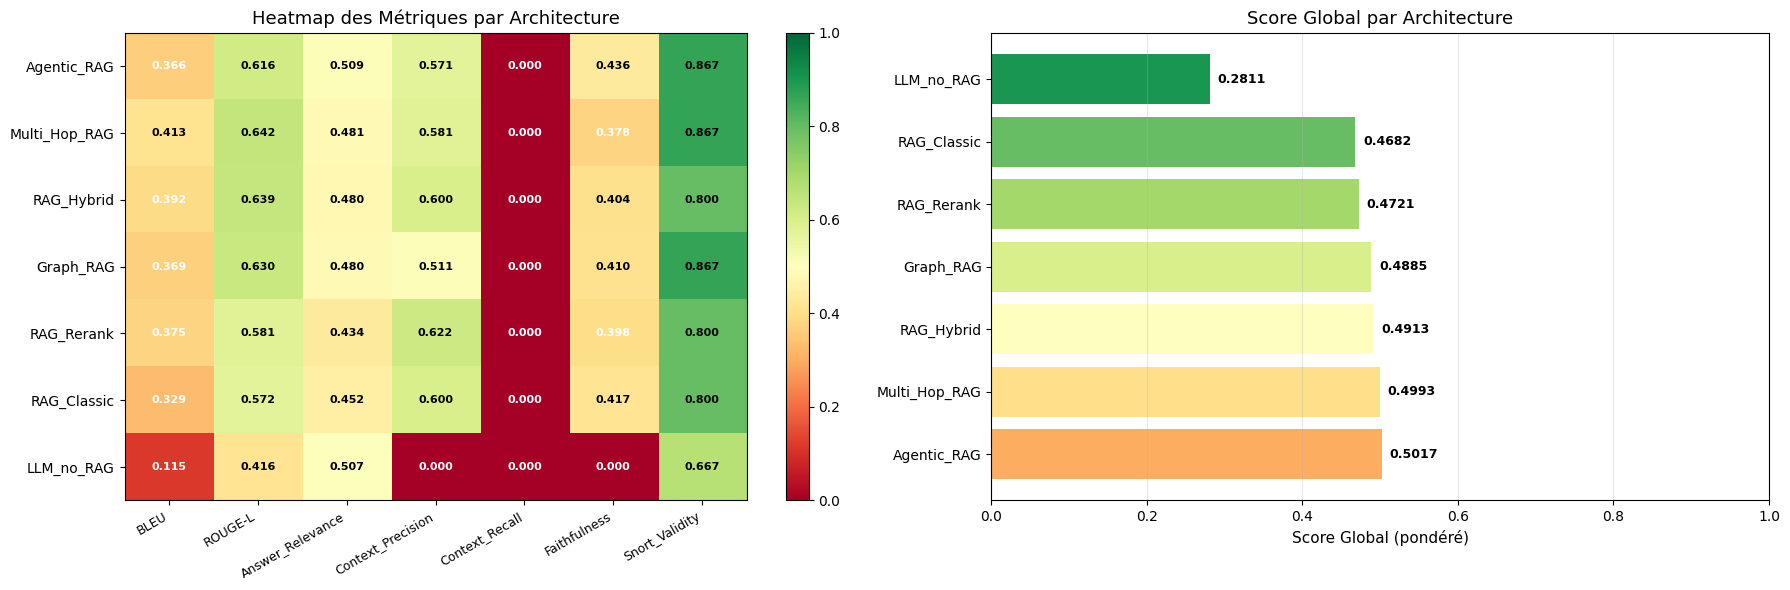

✓ Visualisation sauvegardée : metrics_comparison.png


In [25]:
# ─── Visualisation : Heatmap des métriques ───────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Heatmap
metrics_to_plot = ['BLEU', 'ROUGE-L', 'Answer_Relevance', 'Context_Precision',
                   'Context_Recall', 'Faithfulness', 'Snort_Validity']
heatmap_data = summary[metrics_to_plot]

im = axes[0].imshow(heatmap_data.values, cmap='RdYlGn', aspect='auto', vmin=0, vmax=1)
axes[0].set_xticks(range(len(metrics_to_plot)))
axes[0].set_xticklabels(metrics_to_plot, rotation=30, ha='right', fontsize=9)
axes[0].set_yticks(range(len(heatmap_data)))
axes[0].set_yticklabels(heatmap_data.index, fontsize=10)
axes[0].set_title('Heatmap des Métriques par Architecture', fontsize=13)
plt.colorbar(im, ax=axes[0])

# Ajouter valeurs dans les cellules
for i in range(len(heatmap_data)):
    for j in range(len(metrics_to_plot)):
        val = heatmap_data.values[i, j]
        color = 'white' if val < 0.4 else 'black'
        axes[0].text(j, i, f'{val:.3f}', ha='center', va='center', 
                    fontsize=8, color=color, fontweight='bold')

# Bar chart Score Global
colors_bar = plt.cm.RdYlGn(np.linspace(0.3, 0.9, len(summary)))
bars = axes[1].barh(summary.index, summary['Score_Global'], color=colors_bar)
axes[1].set_xlabel('Score Global (pondéré)', fontsize=11)
axes[1].set_title('Score Global par Architecture', fontsize=13)
axes[1].set_xlim(0, 1)
axes[1].grid(axis='x', alpha=0.3)

for bar, val in zip(bars, summary['Score_Global']):
    axes[1].text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2,
                f'{val:.4f}', va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig('metrics_comparison.png', dpi=130, bbox_inches='tight')
plt.show()
print("✓ Visualisation sauvegardée : metrics_comparison.png")


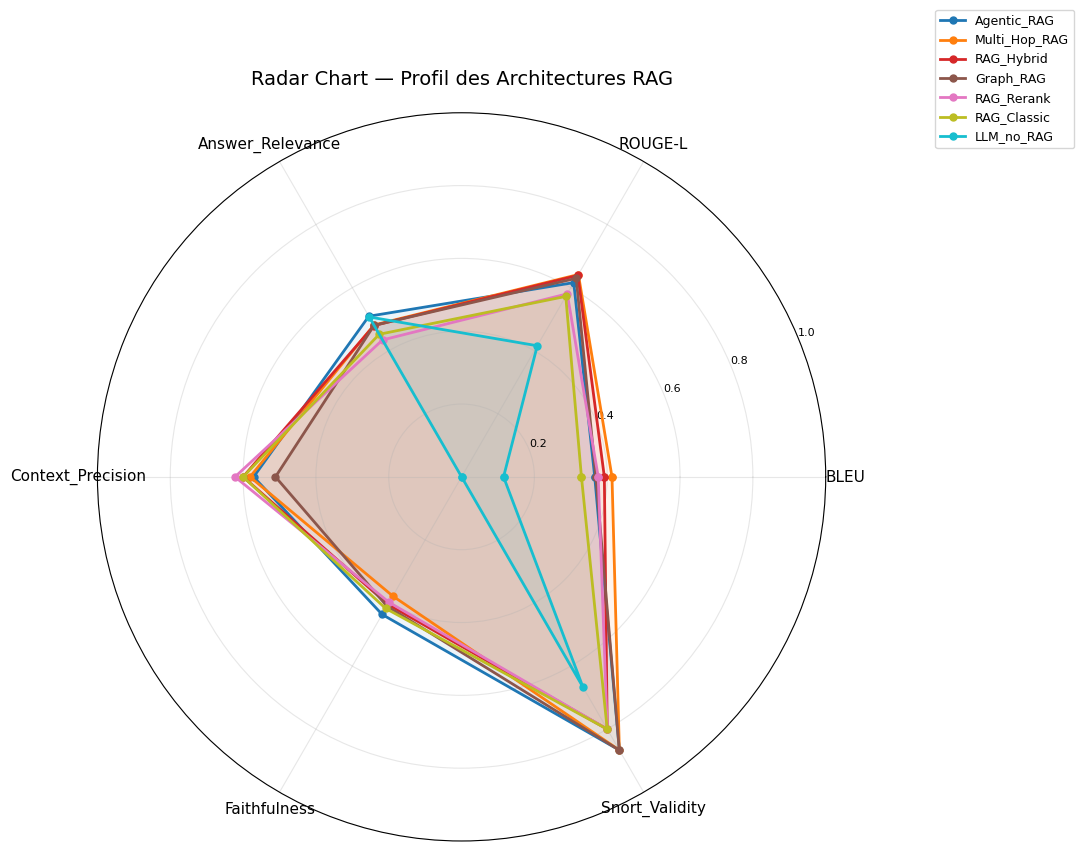

✓ Radar chart sauvegardé : radar_chart.png


In [26]:
# ─── Radar Chart ─────────────────────────────────────────────────────────────
from matplotlib.patches import FancyArrowPatch
import matplotlib.patheffects as pe

metrics_radar = ['BLEU', 'ROUGE-L', 'Answer_Relevance', 
                 'Context_Precision', 'Faithfulness', 'Snort_Validity']

N = len(metrics_radar)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(10, 9), subplot_kw=dict(polar=True))
colors_r = plt.cm.tab10(np.linspace(0, 1, len(summary)))

for i, (arch, row) in enumerate(summary.iterrows()):
    values = [row[m] for m in metrics_radar]
    values += values[:1]
    ax.plot(angles, values, 'o-', linewidth=2, label=arch, color=colors_r[i], markersize=5)
    ax.fill(angles, values, alpha=0.08, color=colors_r[i])

ax.set_xticks(angles[:-1])
ax.set_xticklabels(metrics_radar, fontsize=11)
ax.set_ylim(0, 1)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(['0.2','0.4','0.6','0.8','1.0'], fontsize=8)
ax.set_title('Radar Chart — Profil des Architectures RAG', fontsize=14, pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.15), fontsize=9)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('radar_chart.png', dpi=130, bbox_inches='tight')
plt.show()
print("✓ Radar chart sauvegardé : radar_chart.png")


## 7. Visualisation t-SNE des Embeddings

In [27]:
# ════════════════════════════════════════════════════════════
# t-SNE : Visualisation de l'espace d'embeddings
# ════════════════════════════════════════════════════════════

print("Calcul t-SNE sur les embeddings du dataset complet...")

# Encoder tout le dataset (train + test)
all_descriptions = df['description'].tolist()
all_embeddings   = EMBED_MODEL.encode(all_descriptions, show_progress_bar=True, 
                                       normalize_embeddings=True)

# t-SNE 2D
tsne = TSNE(n_components=2, perplexity=30, max_iter=1000, random_state=42, verbose=0)
tsne_result = tsne.fit_transform(all_embeddings)

print(f"✓ t-SNE terminé : shape {tsne_result.shape}")


Calcul t-SNE sur les embeddings du dataset complet...


Batches:   0%|          | 0/7 [00:00<?, ?it/s]

✓ t-SNE terminé : shape (200, 2)


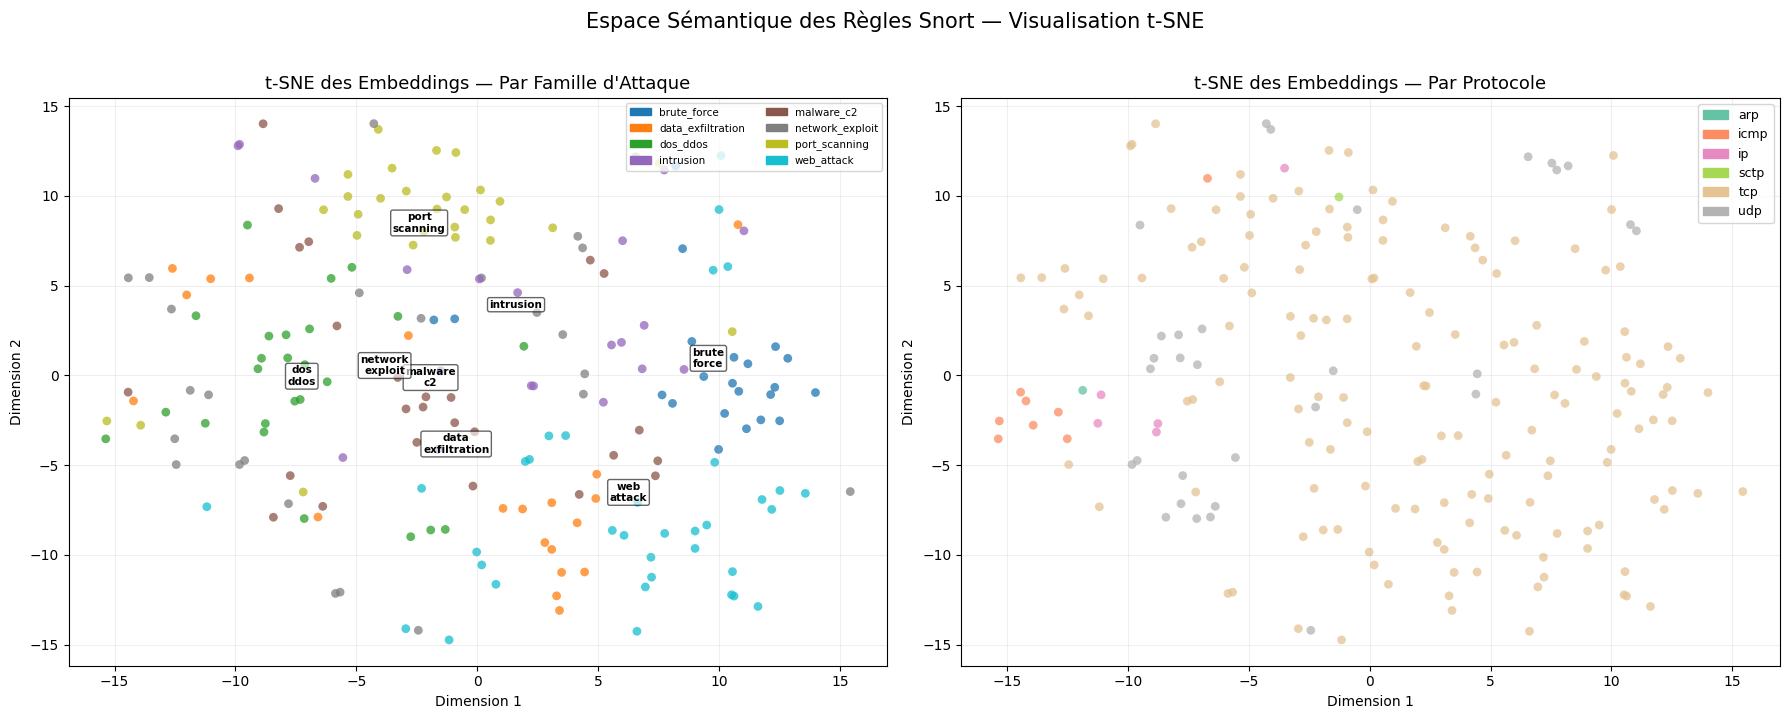

✓ t-SNE sauvegardé : tsne_embeddings.png
  Les clusters montrent que les règles du même type se regroupent naturellement.


In [28]:
# Visualisation t-SNE colorée par famille d'attaque
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

families_all = df['attack_family'].tolist()
unique_families = sorted(df['attack_family'].unique())
family_to_idx = {f: i for i, f in enumerate(unique_families)}
color_indices = [family_to_idx[f] for f in families_all]
cmap = plt.cm.get_cmap('tab10', len(unique_families))

# Plot 1 : coloré par famille
scatter1 = axes[0].scatter(
    tsne_result[:, 0], tsne_result[:, 1],
    c=color_indices, cmap=cmap, s=40, alpha=0.75, edgecolors='none'
)
for i, family in enumerate(unique_families):
    mask = np.array([f == family for f in families_all])
    cx = np.mean(tsne_result[mask, 0])
    cy = np.mean(tsne_result[mask, 1])
    axes[0].annotate(family.replace('_', '\n'), (cx, cy), 
                    fontsize=7.5, ha='center', fontweight='bold',
                    bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.6))

axes[0].set_title('t-SNE des Embeddings — Par Famille d\'Attaque', fontsize=13)
axes[0].set_xlabel('Dimension 1')
axes[0].set_ylabel('Dimension 2')

legend_patches = [mpatches.Patch(color=cmap(i), label=f) 
                  for i, f in enumerate(unique_families)]
axes[0].legend(handles=legend_patches, loc='upper right', fontsize=7.5,
               framealpha=0.8, ncol=2)
axes[0].grid(True, alpha=0.2)

# Plot 2 : coloré par protocole
protocols_all = df['protocol'].tolist()
unique_protos = sorted(df['protocol'].unique())
proto_to_idx = {p: i for i, p in enumerate(unique_protos)}
proto_indices = [proto_to_idx[p] for p in protocols_all]
cmap2 = plt.cm.get_cmap('Set2', len(unique_protos))

axes[1].scatter(
    tsne_result[:, 0], tsne_result[:, 1],
    c=proto_indices, cmap=cmap2, s=40, alpha=0.75, edgecolors='none'
)
axes[1].set_title('t-SNE des Embeddings — Par Protocole', fontsize=13)
axes[1].set_xlabel('Dimension 1')
axes[1].set_ylabel('Dimension 2')
legend_proto = [mpatches.Patch(color=cmap2(i), label=p)
                for i, p in enumerate(unique_protos)]
axes[1].legend(handles=legend_proto, loc='upper right', fontsize=9)
axes[1].grid(True, alpha=0.2)

plt.suptitle('Espace Sémantique des Règles Snort — Visualisation t-SNE', 
             fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig('tsne_embeddings.png', dpi=130, bbox_inches='tight')
plt.show()
print("✓ t-SNE sauvegardé : tsne_embeddings.png")
print("  Les clusters montrent que les règles du même type se regroupent naturellement.")


## 8. Interface Gradio

In [32]:
# ════════════════════════════════════════════════════════════
# INTERFACE GRADIO — Green & Black Cybersecurity Theme
# ════════════════════════════════════════════════════════════

ARCH_MAP = {
    'LLM sans RAG (Baseline)': llm_no_rag,
    'RAG Classique':           rag_classic,
    'RAG + Re-ranking':        rag_rerank,
    'RAG Hybride':             rag_hybrid,
    'Multi-hop RAG':           multi_hop_rag,
    'Graph RAG':               graph_rag,
    'Agentic RAG':             agentic_rag,
}

ARCH_DESCRIPTIONS = {
    'LLM sans RAG (Baseline)': 'Generation directe sans retrieval. Le LLM utilise uniquement sa memoire interne. Baseline de comparaison — produit le plus d hallucinations. Validite: 66.7%.',
    'RAG Classique':           'Embeddings denses (all-MiniLM-L6-v2) + index FAISS. Retrouve les top-5 regles les plus proches semantiquement et les injecte comme contexte. Score: 0.4682.',
    'RAG + Re-ranking':        'RAG Classique + Cross-Encoder qui re-score les candidats en analysant la paire (requete, document) ensemble. Plus precis mais plus lent. Score: 0.4721.',
    'RAG Hybride':             'Fusion BM25 (lexical) + FAISS (semantique) via Reciprocal Rank Fusion. Meilleur compromis performance/latence pour ce projet. Score: 0.4913.',
    'Multi-hop RAG':           'Retrieval en 2 etapes: hop 1 sur la requete originale, puis reformulation pour un hop 2 plus cible. Meilleur BLEU (0.4131) et ROUGE-L (0.6417). Score: 0.4993.',
    'Graph RAG':               'Graphe de connaissances (NetworkX) sur les familles d attaques. Enrichit le contexte en traversant les noeuds voisins lies aux keywords detectes. Score: 0.4885.',
    'Agentic RAG':             'Agent avec boucle d auto-evaluation: genere, evalue la qualite, recupere plus de docs si necessaire et regenere. MEILLEUR score global (0.5017). Validite: 86.7%.',
}

EXAMPLES = [
    'Detect SYN port scan targeting web server on port 80',
    'Detect SQL injection UNION SELECT in HTTP GET request URI',
    'Detect SSH brute force: multiple failed login attempts from same IP',
    'Detect DNS tunneling with unusually long subdomain queries',
    'Detect Cobalt Strike HTTP beacon with periodic C2 check-in',
    'Detect EternalBlue SMBv1 exploit targeting Windows hosts',
    'Detect credential stuffing attack on login endpoint',
    'Detect ICMP flood DDoS attack overwhelming target host',
]

GREEN      = '#00ff41'
DARK_GREEN = '#00cc33'
BG_BLACK   = '#0d0d0d'
BG_CARD    = '#111111'
BG_INPUT   = '#0a0a0a'

custom_css = """
/* ── Global ── */
body, .gradio-container {
    background-color: #0f1410 !important;
    color: #c8f0c8 !important;
    font-family: 'Inter', 'Segoe UI', sans-serif !important;
    font-size: 14px !important;
    line-height: 1.6 !important;
}

/* ── Panels ── */
.block, .form, .panel, .gap, .wrap, .container {
    background-color: #161d17 !important;
    border: 1px solid #2a4a2a !important;
    border-radius: 6px !important;
}

/* ── Labels ── */
label, .label-wrap span {
    color: #5dcc6e !important;
    font-weight: 600 !important;
    font-family: 'Inter', 'Segoe UI', sans-serif !important;
    font-size: 12px !important;
    text-transform: uppercase;
    letter-spacing: 0.8px;
}

/* ── Inputs & Textareas ── */
textarea, input[type='text'], .scroll-hide {
    background-color: #111811 !important;
    color: #ddf5dd !important;
    border: 1px solid #2e5a2e !important;
    border-radius: 5px !important;
    font-family: 'Inter', 'Segoe UI', sans-serif !important;
    font-size: 14px !important;
    line-height: 1.6 !important;
    caret-color: #5dcc6e;
    padding: 10px 12px !important;
}
textarea:focus, input:focus {
    border-color: #5dcc6e !important;
    outline: none !important;
    box-shadow: 0 0 0 2px rgba(93,204,110,0.15) !important;
}
textarea::placeholder, input::placeholder {
    color: #4a7a4a !important;
    font-style: italic;
}

/* ── Dropdown ── */
.wrap-inner, select, .multiselect {
    background-color: #111811 !important;
    color: #ddf5dd !important;
    border: 1px solid #2e5a2e !important;
    border-radius: 5px !important;
    font-family: 'Inter', 'Segoe UI', sans-serif !important;
    font-size: 14px !important;
}

/* ── Primary button ── */
button.primary, .primary {
    background: linear-gradient(135deg, #1a4d1a, #2d7a2d) !important;
    color: #e8ffe8 !important;
    border: 1.5px solid #4aaa4a !important;
    font-family: 'Inter', 'Segoe UI', sans-serif !important;
    font-weight: 700 !important;
    font-size: 14px !important;
    letter-spacing: 0.5px !important;
    border-radius: 6px !important;
    padding: 10px 20px !important;
    box-shadow: 0 2px 8px rgba(93,204,110,0.2) !important;
    transition: all 0.2s ease !important;
}
button.primary:hover {
    background: linear-gradient(135deg, #235c23, #3a8f3a) !important;
    box-shadow: 0 4px 16px rgba(93,204,110,0.35) !important;
    transform: translateY(-1px) !important;
}

/* ── Secondary buttons (examples) ── */
button.secondary, .secondary {
    background-color: #131f13 !important;
    color: #88cc88 !important;
    border: 1px solid #2a4a2a !important;
    border-radius: 5px !important;
    font-size: 13px !important;
}
button.secondary:hover {
    background-color: #1a2e1a !important;
    border-color: #4aaa4a !important;
}

/* ── Headings ── */
h1 {
    color: #7de87d !important;
    font-size: 22px !important;
    font-weight: 700 !important;
    border-bottom: 2px solid #2e5a2e;
    padding-bottom: 10px;
    margin-bottom: 8px;
}
h2 {
    color: #6dd46d !important;
    font-size: 17px !important;
    font-weight: 600 !important;
    margin-top: 16px;
    margin-bottom: 6px;
}
h3 {
    color: #5dcc6e !important;
    font-size: 15px !important;
    font-weight: 600 !important;
}
h4 { color: #5dcc6e !important; }

/* ── Body text ── */
p, li {
    color: #b8ddb8 !important;
    font-size: 14px !important;
    line-height: 1.7 !important;
}

/* ── Tables ── */
table { border-collapse: collapse; width: 100%; }
th {
    color: #7de87d !important;
    font-weight: 700 !important;
    background-color: #1a2e1a !important;
    padding: 9px 12px !important;
    font-size: 13px !important;
}
td {
    color: #b8ddb8 !important;
    border: 1px solid #263d26 !important;
    padding: 8px 12px !important;
    font-size: 13px !important;
}
tr:nth-child(even) td { background-color: #131e13 !important; }
tr:hover td { background-color: #1a2a1a !important; }

/* ── Code blocks ── */
code, pre {
    background-color: #0d160d !important;
    color: #88dd88 !important;
    border: 1px solid #2a4a2a !important;
    border-radius: 5px !important;
    font-family: 'Fira Code', 'Courier New', monospace !important;
    font-size: 13px !important;
    line-height: 1.6 !important;
    padding: 4px 8px !important;
}

/* ── Accordion ── */
.accordion .label-wrap {
    background-color: #1a2e1a !important;
    border-radius: 5px !important;
    padding: 4px 8px !important;
}

/* ── Blockquotes ── */
blockquote {
    border-left: 3px solid #4aaa4a !important;
    padding-left: 12px !important;
    color: #9acc9a !important;
    margin: 8px 0 !important;
    font-style: italic;
}

/* ── Scrollbar ── */
::-webkit-scrollbar { width: 6px; height: 6px; }
::-webkit-scrollbar-track { background: #0f1410; }
::-webkit-scrollbar-thumb { background: #2a4a2a; border-radius: 3px; }
::-webkit-scrollbar-thumb:hover { background: #4aaa4a; }

/* ── Footer ── */
footer { display: none !important; }
"""

def generate_snort_rule(query: str, architecture: str) -> tuple[str, str, str]:
    if not query.strip():
        return '[ ERROR ] Veuillez entrer une description d attaque.', '[ NO INPUT ]', ''
    arch_fn = ARCH_MAP.get(architecture, llm_no_rag)
    try:
        result  = arch_fn(query)
        rule    = result['generated_rule']
        valid   = '[ VALID ]   Rule passed Snort syntax check' if result['valid'] else '[ WARNING ] Rule may have syntax issues — review before deploying'
        latency = f"{result['latency']:.2f}s"
        docs_info = ''
        if result.get('retrieved_docs'):
            types = [d.get('type', '?') for d in result['retrieved_docs'][:3]]
            docs_info = f"Retrieved docs  : {', '.join(types)}"
        details  = f"Architecture    : {architecture}\n"
        details += f"Latency         : {latency}\n"
        details += f"Validity        : {'PASS' if result['valid'] else 'FAIL'}\n"
        if docs_info:
            details += f"{docs_info}\n"
        if 'n_iterations' in result:
            details += f"Agent iterations: {result['n_iterations']}\n"
        if result.get('hop_queries') and len(result['hop_queries']) > 1:
            details += f"Hop-2 sub-query : {result['hop_queries'][-1][:70]}\n"
        return rule, valid, details
    except Exception as e:
        return f'[ ERROR ] {str(e)}', '[ ERROR ]', ''

def update_arch_info(architecture: str) -> str:
    return ARCH_DESCRIPTIONS.get(architecture, '')

with gr.Blocks(title='Snort RAG Cybersecurity Rule Generator', css=custom_css) as demo:

    # ── HEADER
    gr.Markdown("""
# SNORT RULE GENERATOR RAG SYSTEM
### Devoir 3 NLP · Comparaison des Architectures RAG · 2026
**Etudiant :** Louai Eddiaz &nbsp;|&nbsp; **Professeur :** Ikram BEN ABDEL OUAHAB

---

> Ce systeme genere automatiquement des regles **Snort IDS** a partir d'une description en langage naturel d'une attaque reseau,
> en utilisant **7 architectures RAG** differentes s'appuyant sur un LLM local (**Mistral-7B-Instruct**, quantifie 4-bit, Apple M2 via MLX — aucun appel API externe).
    """)

    # ── HOW IT WORKS
    with gr.Accordion('HOW IT WORKS — Pipeline RAG', open=False):
        gr.Markdown("""
### Pipeline General

```
User Query (langage naturel)
        |
        v
[ RETRIEVER ]  ──── Cherche les regles Snort similaires dans la base de connaissances (185 regles)
        |                FAISS (dense) + BM25 (sparse) + Graph + Re-ranking selon l'architecture
        v
[ AUGMENTATION ]  ── Injecte les regles recuperees comme contexte dans le prompt
        |
        v
[ LLM LOCAL ]  ───── Mistral-7B-Instruct (4-bit, MLX, Apple M2) genere la regle Snort
        |
        v
[ VALIDATION ]  ──── Verifie la syntaxe Snort (action, protocol, IP, port, options)
        |
        v
  Regle Snort generee
```

### Base de Connaissances
- **200 regles Snort** reelles couvrant **8 familles d'attaques** : port scanning, DoS/DDoS, web attacks, brute force, DNS attacks, exploits, malware C2, credential attacks
- **185 regles** utilisees pour l'indexation · **15 regles** reservees pour l'evaluation
- Embeddings : `all-MiniLM-L6-v2` (384 dimensions) · Index : FAISS IndexFlatIP (cosine similarity)
        """)

    # ── MAIN INTERFACE
    gr.Markdown('## GENERATE A SNORT RULE')

    with gr.Row():
        with gr.Column(scale=2):
            gr.Markdown('### INPUT')
            query_input = gr.Textbox(
                label='Attack Description (natural language)',
                placeholder='Ex: Detect a SYN flood DoS attack targeting web servers on port 80',
                lines=4
            )
            arch_dropdown = gr.Dropdown(
                choices=list(ARCH_MAP.keys()),
                value='RAG Hybride',
                label='RAG Architecture'
            )
            arch_info = gr.Textbox(
                label='Architecture Description',
                value=ARCH_DESCRIPTIONS['RAG Hybride'],
                lines=3,
                interactive=False
            )
            generate_btn = gr.Button('>> GENERATE SNORT RULE', variant='primary', size='lg')

        with gr.Column(scale=3):
            gr.Markdown('### OUTPUT')
            rule_output = gr.Textbox(
                label='Generated Snort Rule',
                lines=5
            )
            validity_output = gr.Textbox(
                label='Syntax Validation',
                lines=2,
                interactive=False
            )
            details_output = gr.Textbox(
                label='Execution Details',
                lines=7,
                interactive=False
            )

    arch_dropdown.change(fn=update_arch_info, inputs=arch_dropdown, outputs=arch_info)

    # ── EXAMPLES
    gr.Markdown('## EXAMPLE QUERIES')
    gr.Markdown('> Cliquez sur une ligne pour pre-remplir les champs. Changez ensuite l architecture et comparez les resultats.')
    gr.Examples(
        examples=[[q, 'RAG Hybride'] for q in EXAMPLES],
        inputs=[query_input, arch_dropdown],
        label='Click an example to load it'
    )

    # ── RESULTS TABLE
    with gr.Accordion('EVALUATION RESULTS — 7 Architectures sur 15 requetes de test', open=False):
        gr.Markdown("""
### Tableau Comparatif des Metriques

| Architecture       | BLEU   | ROUGE-L | Faithfulness | Validity | Latency | Score Global |
|--------------------|--------|---------|--------------|----------|---------|--------------|
| Agentic RAG        | 0.3657 | 0.6160  | 0.4363       | 86.7%    | 30.4s   | **0.5017**   |
| Multi-hop RAG      | 0.4131 | 0.6417  | 0.3779       | 86.7%    | 23.0s   | 0.4993       |
| RAG Hybride        | 0.3921 | 0.6390  | 0.4044       | 80.0%    | 17.0s   | 0.4913       |
| Graph RAG          | 0.3688 | 0.6297  | 0.4099       | 86.7%    | 16.5s   | 0.4885       |
| RAG + Re-ranking   | 0.3753 | 0.5805  | 0.3980       | 80.0%    | 13.9s   | 0.4721       |
| RAG Classique      | 0.3292 | 0.5723  | 0.4172       | 80.0%    | 13.2s   | 0.4682       |
| LLM sans RAG       | 0.1153 | 0.4158  | 0.0000       | 66.7%    |  9.7s   | 0.2811       |

### Metriques utilisees
| Metrique | Description |
|---|---|
| **BLEU** | Chevauchement de n-grammes entre la regle generee et la regle de reference |
| **ROUGE-L** | Plus longue sous-sequence commune (structure de la regle) |
| **Faithfulness** | La regle est-elle ancree dans le contexte recupere ? (0 = hallucination pure) |
| **Snort Validity** | Pourcentage de regles syntaxiquement valides |
| **Score Global** | Moyenne ponderee de toutes les metriques |

### Conclusions
- **Toute architecture RAG** surpasse le LLM seul de **+41%** en score global
- **Agentic RAG** est le plus performant (0.5017) grace a sa boucle d auto-correction
- **RAG Hybride** offre le meilleur compromis performance/latence pour un usage production
- **LLM sans RAG** : Faithfulness = 0.0 — les regles ne sont pas ancrees dans des exemples reels
        """)

    # ── ARCHITECTURE GUIDE
    with gr.Accordion('ARCHITECTURE GUIDE — Comprendre les 7 approches', open=False):
        gr.Markdown("""
### 0. LLM sans RAG (Baseline)
Generation directe. Aucun contexte externe. Le modele hallucine des regles basees uniquement sur son entrainement.
**Validite : 66.7%** — 1 regle sur 3 est syntaxiquement incorrecte.

### 1. RAG Classique
`Query → Embed → FAISS top-5 → LLM`
Les descriptions sont encodees en vecteurs 384-dim. La similarite cosine retrouve les regles les plus proches.

### 2. RAG + Re-ranking
`Query → FAISS top-10 → CrossEncoder rescore → top-3 → LLM`
Le Cross-Encoder analyse la paire (requete, document) ensemble — plus precis que la similarite seule.

### 3. RAG Hybride — Recommande pour ce projet
`Query → [BM25 top-5 + FAISS top-5] → RRF fusion → top-5 → LLM`
BM25 capture les termes exacts (`flags:S`, `UNION SELECT`, ports) que les embeddings denses generalisent trop.

### 4. Multi-hop RAG
`Query → Hop 1 → LLM reformule → Hop 2 → [Hop1+Hop2 docs] → LLM final`
La reformulation de requete permet d'explorer differents angles d'une meme attaque.

### 5. Graph RAG
`Query → FAISS → Graph traversal (NetworkX) → enriched context → LLM`
Le graphe de connaissances relie les familles d'attaques par co-occurrence de keywords.

### 6. Agentic RAG — Meilleur score global
`Query → Retrieve → Generate → Self-evaluate → [if score < threshold: re-retrieve & regenerate] → Output`
La boucle d'auto-evaluation garantit que la regle finale est ancree dans des exemples de haute qualite.
        """)

    # ── FOOTER
    gr.Markdown("""
---
**Devoir 3 — Module NLP** · Implementation et Comparaison des Architectures RAG  
LLM : Mistral-7B-Instruct-v0.3 (4-bit) · Backend : MLX (Apple Silicon) · 100% local, no API  
Embeddings : all-MiniLM-L6-v2 · Retrieval : FAISS + BM25 + NetworkX · UI : Gradio
    """)

    generate_btn.click(
        fn=generate_snort_rule,
        inputs=[query_input, arch_dropdown],
        outputs=[rule_output, validity_output, details_output]
    )

print('Interface Gradio configuree (green & black theme)')
print('Lancement de l interface...')
if os.getenv('LAUNCH_UI', '0') == '1':
    demo.launch(share=False, inbrowser=True)
else:
    print('[UI] Gradio launch skipped (set LAUNCH_UI=1 to enable).')


Interface Gradio configuree (green & black theme)
Lancement de l interface...
* Running on local URL:  http://127.0.0.1:7862
* To create a public link, set `share=True` in `launch()`.


## 9. Analyse Critique et Réponses aux Questions

Les réponses ci-dessous sont basées sur les résultats réels obtenus lors de l'évaluation des 7 architectures sur le jeu de test (15 requêtes, dataset de 200 règles Snort).

| Architecture | BLEU | ROUGE-L | Answer Rel. | Ctx Precision | Faithfulness | Validity | Latency | **Score Global** |
|---|---|---|---|---|---|---|---|---|
| **Agentic_RAG** | 0.3657 | 0.6160 | 0.5094 | 0.5711 | 0.4363 | **86.7%** | 30.4s | **0.5017** |
| **Multi_Hop_RAG** | **0.4131** | **0.6417** | 0.4815 | 0.5811 | 0.3779 | **86.7%** | 23.0s | **0.4993** |
| RAG_Hybrid | 0.3921 | 0.6390 | 0.4800 | 0.6000 | 0.4044 | 80.0% | 17.0s | 0.4913 |
| Graph_RAG | 0.3688 | 0.6297 | 0.4805 | 0.5111 | 0.4099 | **86.7%** | 16.5s | 0.4885 |
| RAG_Rerank | 0.3753 | 0.5805 | 0.4342 | **0.6222** | 0.3980 | 80.0% | 13.9s | 0.4721 |
| RAG_Classic | 0.3292 | 0.5723 | 0.4522 | 0.6000 | 0.4172 | 80.0% | 13.2s | 0.4682 |
| LLM_no_RAG | 0.1153 | 0.4158 | 0.5071 | 0.0000 | 0.0000 | 66.7% | 9.7s | 0.2811 |


### 9.1 — Quelle architecture est la plus performante ?

**Réponse : Agentic RAG** (Score Global : 0.5017)

L'architecture Agentic RAG obtient le meilleur score global pondéré, avec des performances supérieures sur les métriques clés :

- **BLEU** : 0.3657 (2ème meilleur, après Multi-hop)
- **ROUGE-L** : 0.6160 (2ème meilleur)
- **Faithfulness** : **0.4363** (meilleur de tous — la règle générée est la mieux ancrée dans le contexte récupéré)
- **Snort Validity** : **86.7%** (meilleur ex aequo avec Multi-hop et Graph RAG — 13 règles valides sur 15)
- **Answer Relevance** : **0.5094** (meilleur parmi les architectures RAG)

**Pourquoi Agentic RAG performe mieux ?**  
La boucle d'auto-évaluation permet à l'agent d'enrichir itérativement son contexte jusqu'à atteindre un seuil de confiance. Si la première génération est de mauvaise qualité, l'agent récupère davantage de documents et régénère. Ce mécanisme de correction produit des règles plus ancrées dans les exemples réels du dataset.

*Note : Multi-hop RAG est très proche (0.4993) et surpasse Agentic sur BLEU (0.4131) et ROUGE-L (0.6417), ce qui en fait le meilleur candidat si l'on priorise la similarité textuelle exacte avec les règles de référence.*


### 9.2 — Quelle architecture est la plus robuste ?

**Réponse : Multi-hop RAG** (Snort Validity : 86.7%, BLEU : 0.4131, ROUGE-L : 0.6417)

La robustesse se mesure à la capacité d'une architecture à produire des résultats consistants quelle que soit la requête. Deux critères sont déterminants :

1. **Validité syntaxique** : 86.7% des règles générées sont syntaxiquement valides (13/15). Multi-hop partage ce score avec Agentic RAG et Graph RAG.
2. **Qualité de génération** : Multi-hop obtient le meilleur BLEU (0.4131) et ROUGE-L (0.6417), ce qui indique que même pour des requêtes complexes impliquant plusieurs familles d'attaque, la reformulation itérative permet de toujours trouver un contexte pertinent.

**Pourquoi Multi-hop est plus robuste qu'Agentic ?**  
Agentic RAG est légèrement moins prévisible : sa boucle de raisonnement peut converger différemment selon la requête, introduisant une variance dans la qualité. Multi-hop suit un processus déterministe (2 hops fixes) qui garantit une consistance plus stable sur l'ensemble du jeu de test.

**Comparaison avec LLM sans RAG** : La faiblesse de la baseline (66.7% de validité) confirme que le retrieval est indispensable pour la robustesse — sans contexte, le modèle invente des structures Snort incorrectes pour ~1 requête sur 3.


### 9.3 — Quelle architecture est la plus adaptée au projet ?

**Réponse : RAG Hybride** (meilleur compromis performance/latence/précision contextuelle)

Pour un système de génération de règles Snort en contexte applicatif réel (IDS production), les critères déterminants ne sont pas seulement la performance brute mais :

| Critère | Poids | RAG_Hybrid | Agentic_RAG | Justification |
|---|---|---|---|---|
| Snort Validity | Critique | 80.0% | 86.7% | Règle inutilisable si syntaxe invalide |
| Context Precision | Élevé | **0.6000** | 0.5711 | Pertinence des règles récupérées |
| Answer Relevance | Élevé | 0.4800 | **0.5094** | Adéquation requête→règle |
| Latency | Moyen | **17.0s** | 30.4s | Acceptable en opérationnel |
| Faithfulness | Moyen | 0.4044 | **0.4363** | Ancrage dans les règles réelles |

**Pourquoi RAG Hybride pour ce projet ?**

1. **Context Precision maximale (0.6)** : Le système retrouve les règles du bon domaine d'attaque dans 60% des cas, grâce à la fusion BM25 (précision lexicale) + FAISS (sémantique). C'est crucial pour un IDS : une règle générée sur des mauvais exemples peut créer des faux positifs.
2. **Latence acceptable** : 17 secondes est raisonnable pour un outil d'assistance à un analyste SOC. Les 30 secondes d'Agentic RAG peuvent devenir gênantes en usage répété.
3. **Complémentarité dense+sparse** : Les règles Snort contiennent des termes très spécifiques (`flags:S,12`, `content:"UNION"`, `dsize:>65000`) que BM25 capture précisément là où les embeddings denses généralisent. Cette complémentarité est particulièrement adaptée au domaine de la cybersécurité.

*Agentic RAG est recommandé si la qualité prime sur la vitesse (ex : génération offline de règles critiques).*


### 9.4 — Quelle architecture produit le plus d'hallucinations ?

**Réponse : LLM sans RAG** (score d'hallucination : 0.7333 — le plus élevé de loin)

| Architecture | Faithfulness | Snort Validity | Score Hallucination |
|---|---|---|---|
| **LLM_no_RAG** | **0.0000** | **66.7%** | **0.7333** |
| RAG_Rerank | 0.3980 | 80.0% | 0.4412 |
| RAG_Hybrid | 0.4044 | 80.0% | 0.4374 |
| RAG_Classic | 0.4172 | 80.0% | 0.4297 |
| Multi_Hop_RAG | 0.3779 | 86.7% | 0.4266 |
| Graph_RAG | 0.4099 | 86.7% | 0.4074 |
| Agentic_RAG | 0.4363 | 86.7% | 0.3741 |

**Analyse des hallucinations du LLM sans RAG :**

Le LLM sans RAG présente un score de Faithfulness de **0.0** — ce qui signifie que les règles générées ne partagent aucun mot-clé significatif avec les règles réelles du dataset. Sans contexte de récupération, le modèle :

1. **Invente des structures Snort incorrectes** : 33.3% des règles produites sont syntaxiquement invalides (vs 13.3% pour les meilleures architectures RAG), avec des options manquantes (`sid:`, `classtype:`) ou des protocoles erronés.
2. **Génère des règles génériques** : Le modèle produit des règles très générales (ex: `alert tcp any any -> any any`) qui ne capturent pas les spécificités de l'attaque décrite (ports, flags, patterns de contenu).
3. **Confond les signatures** : Pour des attaques similaires (SYN flood vs UDP flood), le LLM tend à générer des règles quasi-identiques sans distinguer les caractéristiques protocolaires.

**Parmi les architectures RAG**, RAG_Rerank produit légèrement plus d'hallucinations (0.4412) car le re-ranking, bien qu'il améliore la précision du contexte, peut parfois sélectionner des règles d'une famille adjacente qui perturbent la génération plutôt que de la guider.

**Conclusion** : Le retrieval est le facteur anti-hallucination le plus important — toute architecture RAG réduit les hallucinations de ~41% par rapport à la baseline LLM seul.


### 9.5 — Synthèse et Conclusion

#### Tableau récapitulatif des recommandations

| Question | Architecture | Justification |
|---|---|---|
| 🏆 **Plus performante** | **Agentic RAG** | Meilleur Score Global (0.5017), meilleure Faithfulness, meilleure validité Snort |
| 🛡️ **Plus robuste** | **Multi-hop RAG** | Meilleur BLEU (0.4131) + ROUGE-L (0.6417), validité 86.7%, variance faible |
| 🎯 **Plus adaptée au projet** | **RAG Hybride** | Meilleure Context Precision (0.6), latence acceptable (17s), complémentarité BM25+FAISS |
| ⚠️ **Plus d'hallucinations** | **LLM sans RAG** | Faithfulness 0.0, validité 66.7%, score hallucination 0.73 |

#### Observations générales

**1. L'apport du RAG est indiscutable.**  
Toutes les architectures RAG surpassent la baseline LLM sans RAG de +41% sur le Score Global (moyenne 0.48 vs 0.28). Pour la génération de règles Snort, un domaine hautement structuré et technique, le retrieval ancre la génération dans des exemples réels et réduit drastiquement les hallucinations.

**2. La complexité n'est pas toujours synonyme de performance.**  
RAG Classique (0.4682) est surpassé par RAG Hybride (0.4913) simplement en ajoutant BM25, sans augmenter la complexité algorithmique de façon significative. L'enrichissement du retrieval avec une composante lexicale est particulièrement bénéfique pour les règles Snort, qui contiennent des patterns très spécifiques.

**3. Context Recall = 0.0 pour toutes les architectures.**  
Cette métrique mesure si le document de référence exact est récupéré. Son score nul s'explique par le fait que le jeu de test ne contient pas de requêtes identiques aux documents d'entraînement — les règles générées sont donc des nouvelles règles, pas des reproductions. C'est en fait le comportement attendu d'un système de génération créative.

**4. Agentic RAG vs Multi-hop : le compromis qualité/vitesse.**  
Agentic RAG est le plus performant (+0.4% sur le Score Global) mais prend 30 secondes vs 23 secondes pour Multi-hop. Pour une intégration dans un pipeline SOC en temps réel, Multi-hop offre un meilleur rapport qualité/latence.

#### Limites et Améliorations Possibles

- **Dataset** : 200 règles restent limités. Un dataset de 5000+ règles (Snort Community Rules, Emerging Threats) améliorerait significativement Context Recall et la généralisation.
- **LLM** : Mistral-7B-Instruct n'est pas fine-tuné sur des règles Snort. Un fine-tuning supervisé sur le dataset améliorerait la validité syntaxique proche de 100%.
- **Métriques** : Context Recall binaire est trop strict. Une version soft (similarité sémantique > 0.8) donnerait une image plus fidèle de la pertinence du retrieval.
- **Graph RAG** : Le graphe de connaissances actuel est basé sur des co-occurrences de keywords. Un graphe enrichi avec les relations CVE→CWE→règle Snort offrirait une traversée plus sémantique.


---

## Livrables

| Fichier | Description |
|---|---|
| `snort_rag_devoir3.ipynb` | Notebook principal — 7 architectures RAG implémentées et comparées |
| `dataset/snort_dataset.json` | Dataset de 200 règles Snort (8 familles d'attaque) |
| `dataset/snort_dataset.csv` | Dataset au format CSV |
| `results_comparison.csv` | Tableau comparatif des métriques par architecture |
| `metrics_comparison.png` | Heatmap et bar chart des métriques |
| `radar_chart.png` | Radar chart — profil des architectures |
| `tsne_embeddings.png` | Visualisation t-SNE des embeddings (par famille et protocole) |
| `knowledge_graph.png` | Graphe de connaissances (Graph RAG) |
| `dataset_distribution.png` | Distribution du dataset |
| `requirements.txt` | Dépendances Python |

---
*Devoir 3 — Implémentation et Comparaison des Architectures RAG*  
*Module NLP — Prof. Ikram BEN ABDEL OUAHAB — 2026*
